# Combining H_001, H_002, H003 with  H_004, H_005, H_006

This is the comparison of informative and uninformative priors

In [1]:
import json
from pathlib import Path
import sys

sys.argv = [""]
import numpyro

numpyro.set_host_device_count(4)
import jax
import jax.numpy as jnp
import diffrax as dfx

# jax.config.update("jax_disable_jit",True)
jax.local_device_count()

import numpy as np
import matplotlib.pyplot as plt
import arviz as az
import xarray
import ICIW_Plots
import tqdm

plt.style.use("ICIWstyle")
plt.rcParams.update(
    {
        "figure.dpi": 600,
        "font.size": 7,
        # "axes.linewidth": 0.8,
        # "axes.spines.top": False,
        # "axes.spines.right": False,
        # "axes.grid": False,
        # "legend.frameon": False,
    }
)

In [2]:
%config InlineBackend.print_figure_kwargs = {'bbox_inches':None}


In [3]:
from HSA_Cam_B_039_numpyro import kl_divergence_between_models
from HSA_Mo_B_012_numpyro import (
    kinetics_model,
    predict,
    generate_synthetic_data,
    calculate_partial_pressures,
    validate_against_holdout,
    sample_prior as sample_informed_prior,
    TRUE_PARAMS,
)
from HSA_Mo_B_011_numpyro import sample_prior as sample_uninformed_prior

In [4]:
ov = [
    # {
    #     "ID": "H_001",
    #     "run_name": "verdant-stack",
    #     "dir": Path("data/verdant-stack"),
    #     "DOE": "Koschany DOE",
    #     "informed_priors": False,
    #     "noise": "heteroscedastic",
    #     "noise_level": 0.1,
    #     "holdout_data": Path("data/test_HSA_Da_B_001.nc"),
    #     "seeds": None,
    #     "idatas": {},
    #     "proposals": {},
    #     "r_obs": {},
    #     "valdatas": {},
    #     "RMSEs": {},
    #     "paramEKLDS": {},
    #     "paramEKLDS_to_prior": {},
    #     "plot_kwargs":{
    #             "color": "C0",
    #             "ls": "--",
    #     }
    # },
    #     {
    #     "ID": "H_004",
    #     "run_name": "volumetric-ballad",
    #     "dir": Path("data/volumetric-ballad"),
    #     "DOE": "Koschany DOE",
    #     "informed_priors": True,
    #     "noise": "heteroscedastic",
    #     "noise_level": 0.1,
    #     "holdout_data": Path("data/test_HSA_Da_B_001.nc"),
    #     "seeds": None,
    #     "idatas": {},
    #     "proposals": {},
    #     "r_obs": {},
    #     "valdatas": {},
    #     "RMSEs": {},
    #     "paramEKLDS": {},
    #     "paramEKLDS_to_prior": {},
    #     "plot_kwargs":{
    #             "color": "C0",
    #             "ls": "dashdot",
    #     }
    # },
    {
        "ID": "H_002",
        "run_name": "maroon-downtown",
        "dir": Path("data/maroon-downtown"),
        "DOE": "paramEKLD DOE",
        "informed_priors": False,
        "noise": "heteroscedastic",
        "noise_level": 0.1,
        "holdout_data": Path("data/test_HSA_Da_B_001.nc"),
        "seeds": None,
        "idatas": {},
        "proposals": {},
        "r_obs": {},
        "valdatas": {},
        "RMSEs": {},
        "paramEKLDS": {},
        "paramEKLDS_to_prior": {},
        "plot_kwargs":{
                "color": "C1",
                "ls": "-",
        }
    },
    {
        "ID": "H_005",
        "run_name": "preliminary-froth",
        "dir": Path("data/preliminary-froth"),
        "DOE": "paramEKLD DOE",
        "informed_priors": True,
        "noise": "heteroscedastic",
        "noise_level": 0.1,
        "holdout_data": Path("data/test_HSA_Da_B_001.nc"),
        "seeds": None,
        "idatas": {},
        "proposals": {},
        "r_obs": {},
        "valdatas": {},
        "RMSEs": {},
        "paramEKLDS": {},
        "paramEKLDS_to_prior": {},
        "plot_kwargs":{
                "color": "C1",
                "ls": "dotted",
        }
    },
    {
        "ID": "H_003",
        "run_name": "persistent-hardcover",
        "dir": Path("data/persistent-hardcover"),
        "DOE": "predEKLD DOE",
        "informed_priors": False,
        "noise": "heteroscedastic",
        "noise_level": 0.1,
        "holdout_data": Path("data/test_HSA_Da_B_001.nc"),
        "seeds": None,
        "idatas": {},
        "proposals": {},
        "r_obs": {},
        "valdatas": {},
        "RMSEs": {},
        "paramEKLDS": {},
        "paramEKLDS_to_prior": {},
        "plot_kwargs":{
                "color": "C2",
                "ls": "-",
        }
    },
        {
        "ID": "H_006",
        "run_name": "spiteful-anaconda",
        "dir": Path("data/spiteful-anaconda"),
        "DOE": "predEKLD DOE",
        "informed_priors": True,
        "noise": "heteroscedastic",
        "noise_level": 0.1,
        "holdout_data": Path("data/test_HSA_Da_B_001.nc"),
        "seeds": None,
        "idatas": {},
        "proposals": {},
        "r_obs": {},
        "valdatas": {},
        "RMSEs": {},
        "paramEKLDS": {},
        "paramEKLDS_to_prior": {},
        "plot_kwargs":{
                "color": "C2",
                "ls": "dotted",
        }
    },
]

In [5]:
def load_files(ov_dict, seed):
    seed_dir = ov_dict["dir"] / f"seed{seed:03d}"
    # print(seed_dir)
    #sum_file = seed_dir / f"experiment_summary.json" #doesnt work for symlink
    sum_file = list(seed_dir.glob(f"experiment_summary*.json"))[0]
    trace_files = sorted(seed_dir.glob(f"trace_*.nc"))
    # print(sum_file)
    test_data = xarray.open_dataset(ov_dict["holdout_data"])
    idatas = []
    valdatas = []
    paramEKLDS = []
    paramEKLDS_to_prior = []
    for i, trace_file in enumerate(tqdm.tqdm(trace_files)):
        idata = az.from_netcdf(trace_file)
        if i == 0:
            if ov_dict["informed_priors"]:
                idata.update(xarray.DataTree.from_dict({"prior": sample_informed_prior(4000).prior}))
            else:
                idata.update(xarray.DataTree.from_dict({"prior": sample_uninformed_prior(4000).prior}))
        else:
            idata.update(
                xarray.DataTree.from_dict({"prior": idatas[i - 1]["posterior"].dataset})
            )
        idatas.append(idata)
        valdata = validate_against_holdout(
            idata,
            test_data,
            num_samples=5000,
        )
        paramEKLD = kl_divergence_between_models(
            idata_new=idata,
            idata_old=idata,
            key_new="posterior",
            key_old="prior",
            var_names=[
                "k0",
                "Ea_k",
                "A_oh",
                "dH_oh",
                "A_h2",
                "dH_h2",
                "A_mix",
                "dH_mix",
                "sigma_r",
            ],
        ).sum()
        paramEKLD_to_prior = kl_divergence_between_models(
            idata_new=idata,
            idata_old=idatas[0],
            key_new="posterior",
            key_old="prior",
            var_names=[
                "k0",
                "Ea_k",
                "A_oh",
                "dH_oh",
                "A_h2",
                "dH_h2",
                "A_mix",
                "dH_mix",
                "sigma_r",
            ],
        ).sum()
        paramEKLDS.append(paramEKLD)
        paramEKLDS_to_prior.append(paramEKLD_to_prior)
        valdatas.append(valdata)
    ov_dict["idatas"][seed] = idatas
    ov_dict["valdatas"][seed] = valdatas
    ov_dict["paramEKLDS"][seed] = paramEKLDS
    ov_dict["paramEKLDS_to_prior"][seed] = paramEKLDS_to_prior
    with open(sum_file, "r") as f:
        exp_summary = json.load(f)
    ov_dict["proposals"][seed] = np.array(exp_summary["trials"][-1]["observed"]["x"])
    ov_dict["r_obs"][seed] = np.array(exp_summary["trials"][-1]["observed"]["y"])

def get_seeds(ov_dict):
    master_file = ov_dict["dir"] / f"multi_seed_summary.json"
    with open(master_file, "r") as f:
        seed_summary = json.load(f)
    seeds = seed_summary["seeds_used"]
    ov_dict["seeds"] = seeds
    return seeds

In [6]:
for ov_dict in ov:
    seeds=get_seeds(ov_dict)
    print(seeds)
    for seed in seeds:
            load_files(ov_dict, seed)
    # load_files(ov_dict)
    # print(ov_dict["r_obs"])

[43, 44, 45, 46, 47]


100%|██████████| 32/32 [00:18<00:00,  1.77it/s]


[42, 43, 44, 45, 46]


100%|██████████| 32/32 [00:19<00:00,  1.68it/s]


[43, 44, 45, 46, 47]


100%|██████████| 32/32 [00:16<00:00,  1.90it/s]


[42, 43, 44, 45, 46]


100%|██████████| 32/32 [00:16<00:00,  1.91it/s]


In [7]:
def bRMSE(postdata, var_name):
    true = postdata.observed_data[var_name].values
    pred = postdata.posterior_predictive[var_name].values
    res = true - pred
    rmse_vals = np.sqrt(np.mean(res**2, axis=2)).squeeze()
    return rmse_vals


def calculate_RMSEs(ov_dict, seed):
    ov_dict["RMSEs"][seed] = None
    for valdata in ov_dict["valdatas"][seed]:
        rmse_da = bRMSE(valdata, "r_pred")
        if ov_dict["RMSEs"][seed] is None:
            ov_dict["RMSEs"][seed] = [rmse_da]
        else:
            ov_dict["RMSEs"][seed].append(rmse_da)
    ov_dict["RMSEs"][seed] = np.array(ov_dict["RMSEs"][seed])

In [8]:
for ov_dict in ov:
    for seed in ov_dict["seeds"]:
        calculate_RMSEs(ov_dict, seed)

In [9]:
ov[0]["RMSEs"][43][-1].shape

(5000,)

In [10]:
for ov_dict in ov:
    print(ov_dict["run_name"])
    for seed in ov_dict["seeds"]:
        print(f"Seed {seed}: RMSE mean = {ov_dict['RMSEs'][seed][-1].mean()}, 95% HDI = {az.hdi(ov_dict['RMSEs'][seed][-1], prob=0.95)}")


maroon-downtown
Seed 43: RMSE mean = 2.4964482699851218e-06, 95% HDI = [5.48062310e-07 5.23144645e-06]
Seed 44: RMSE mean = 3.155856820486984e-06, 95% HDI = [6.13996243e-07 6.38558800e-06]
Seed 45: RMSE mean = 3.4787591212505882e-06, 95% HDI = [6.86258842e-07 6.64951129e-06]
Seed 46: RMSE mean = 3.536433448703353e-06, 95% HDI = [8.50492603e-07 7.54808262e-06]
Seed 47: RMSE mean = 6.644801646503251e-06, 95% HDI = [1.13257217e-06 1.23348349e-05]
preliminary-froth
Seed 42: RMSE mean = 2.587559566693368e-06, 95% HDI = [4.76135365e-07 5.35296962e-06]
Seed 43: RMSE mean = 3.4013211466809787e-06, 95% HDI = [5.68804751e-07 7.27077991e-06]
Seed 44: RMSE mean = 5.498113560552997e-06, 95% HDI = [1.12908571e-06 1.05473297e-05]
Seed 45: RMSE mean = 2.639423573239222e-06, 95% HDI = [6.41885874e-07 5.43942351e-06]
Seed 46: RMSE mean = 4.57288435116229e-06, 95% HDI = [4.59190272e-07 9.62712738e-06]
persistent-hardcover
Seed 43: RMSE mean = 2.1543293016127895e-06, 95% HDI = [4.86271142e-07 4.14391740e-

### Predictive accuracy

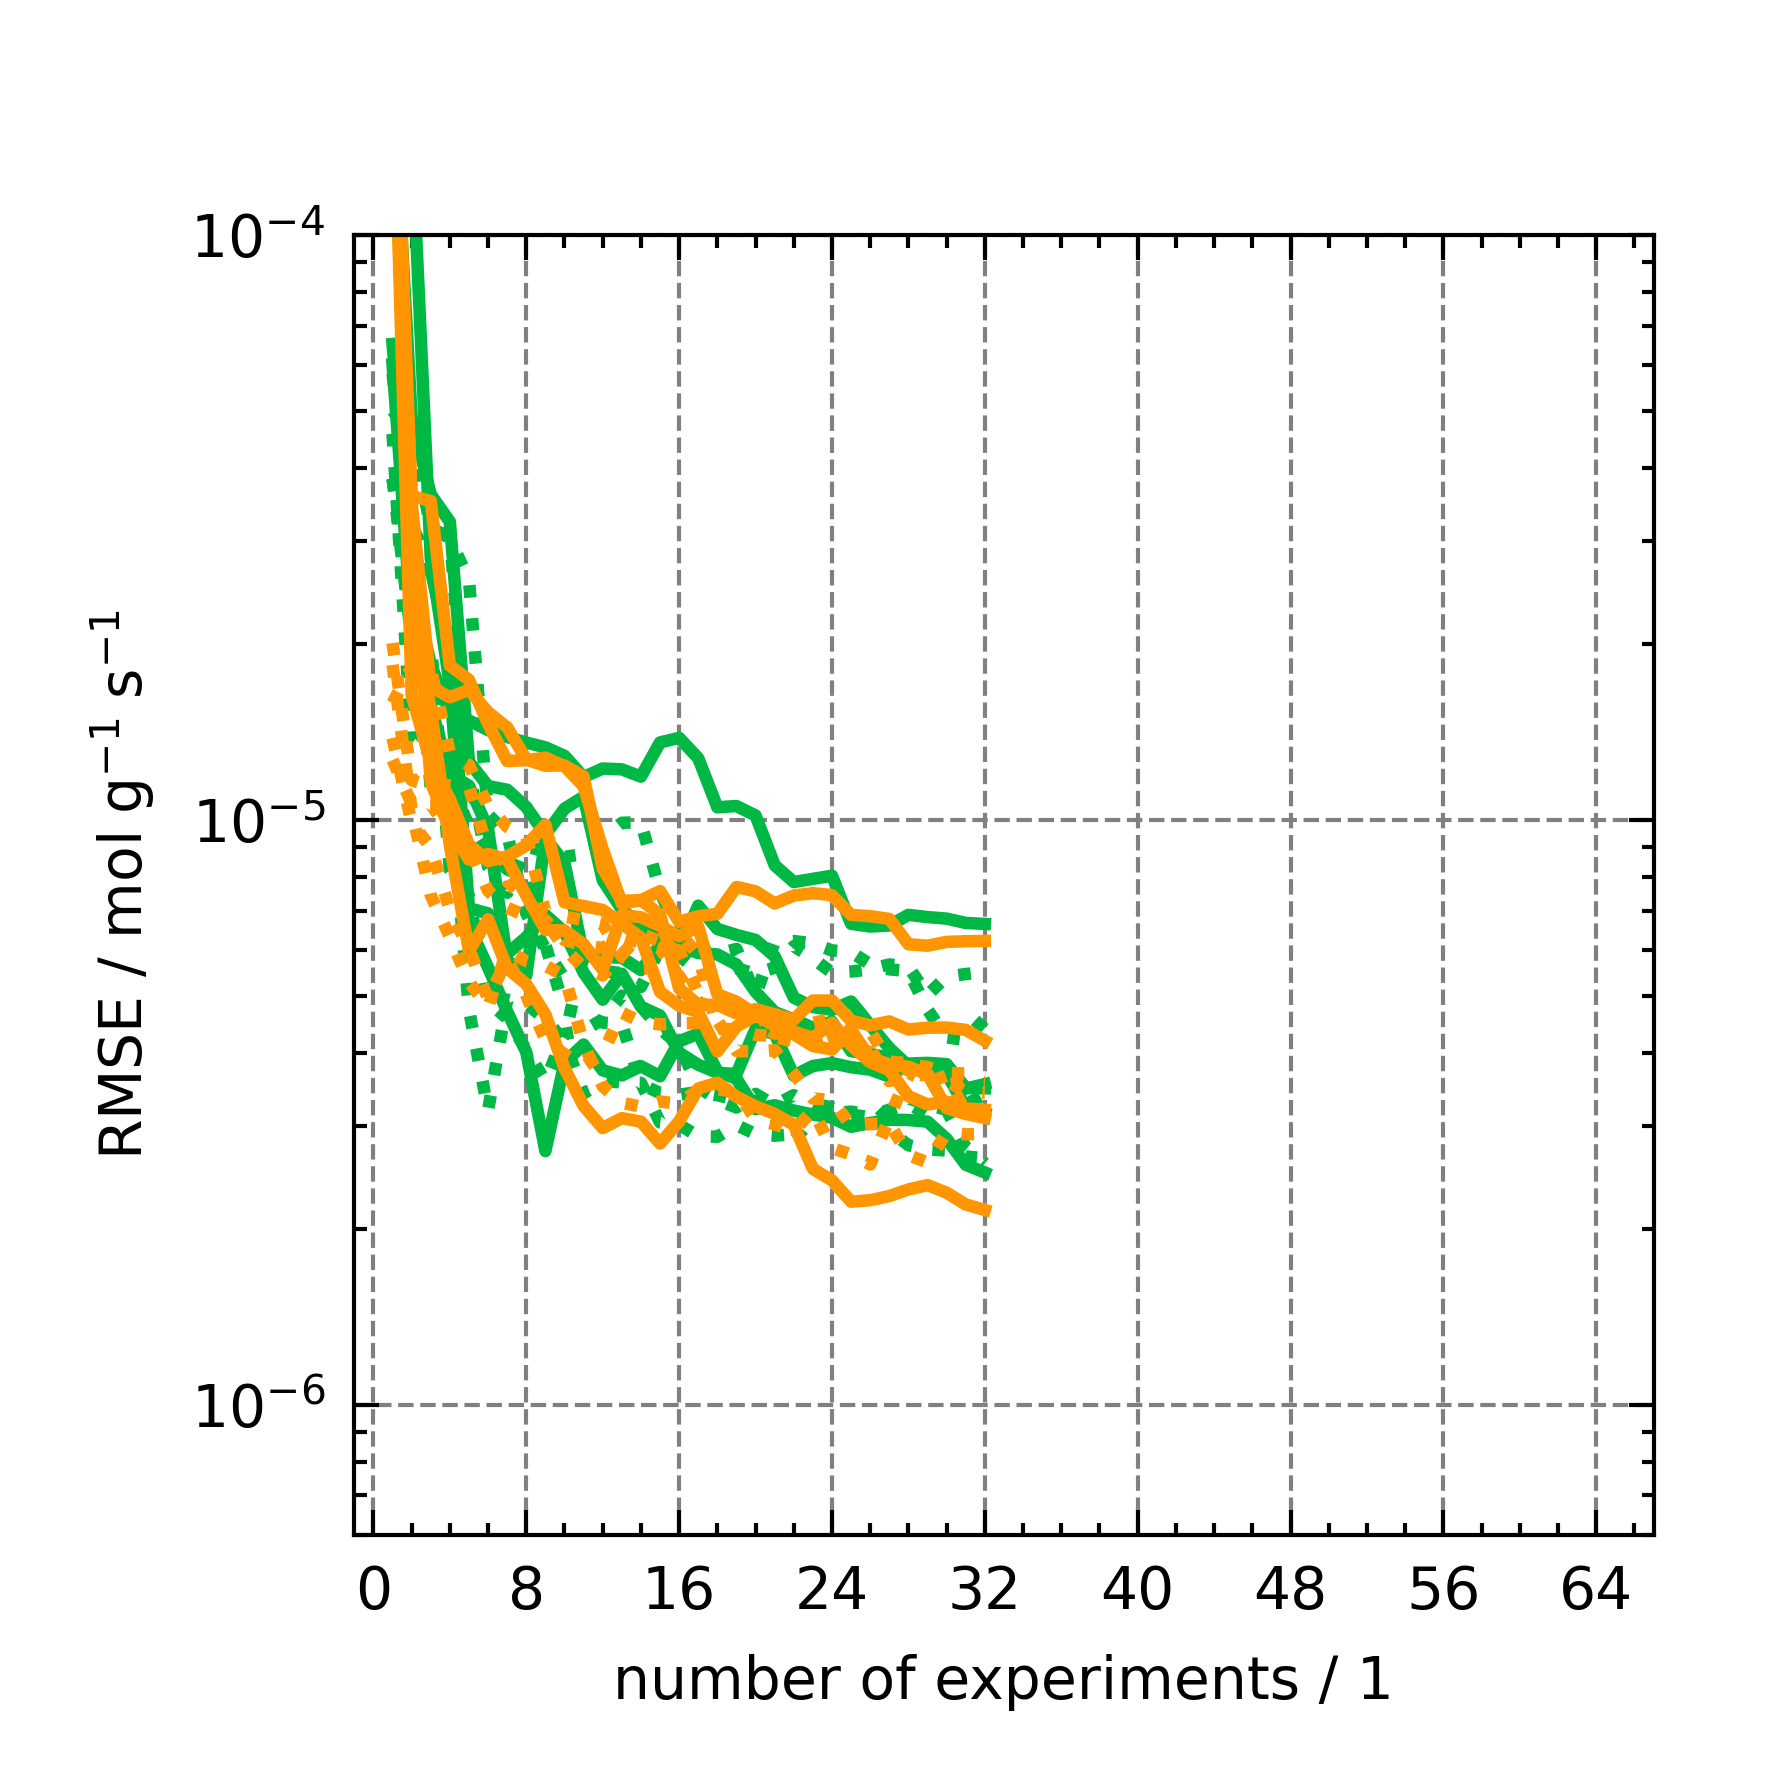

In [11]:
fig = ICIW_Plots.figure()
ax = ICIW_Plots.make_square_ax(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    xlabel="number of experiments / 1",
    ylabel=r"RMSE / $\mathrm{mol}\;\mathrm{g}^{-1}\;\mathrm{s}^{-1}$",
    yscale="log",
    ylim=(6e-7, 1e-4),
    xlim=(-1, 67),
    xticks=[0, 8, 16, 24, 32, 40, 48, 56, 64],
    left_h=1.5 * ICIW_Plots.cm2inch,
)

colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
for i, ov_dict in enumerate(ov):
    for seed in ov_dict["seeds"]:

        if ov_dict["DOE"] in ["Koschany DOE", "LHS32 DOE", "LHS64 DOE"]:
            ax.hlines(
                np.mean(ov_dict["RMSEs"][seed], axis=1)[-1],
                xmin=-1,
                xmax=64,
                label=ov_dict["DOE"],
                ls="--",
                color=colors[i],
            )
            # HDI = az.hdi(ov_dict["RMSEs"][seed][-1], prob=0.95)
            # ax.fill_between(
            #     np.arange(-1, len(ov_dict["RMSEs"][seed]) + 1),
            #     HDI[0],
            #     HDI[1],
            #     alpha=0.2,
            #     # ls="--",
            #     facecolor=colors[i],
            #     # edgecolor="gray",
            # )
            continue
        ax.plot(
            np.arange(1, len(ov_dict["RMSEs"][seed]) + 1),
            np.mean(ov_dict["RMSEs"][seed], axis=1),
            label=ov_dict["DOE"],
            **ov_dict["plot_kwargs"],
        )
        # HDI = az.hdi(ov_dict["RMSEs"][seed].T, prob=0.95)
        # print(HDI.shape)
        # ax.fill_between(
        #     np.arange(1, len(ov_dict["RMSEs"][seed]) + 1),
        #     HDI[:, 0],
        #     HDI[:, 1],
        #     alpha=0.2,
        #     # ls="--",
        #     facecolor=colors[i],
        #     # edgecolor="gray",
        # )
    # ax.legend(frameon=True)

# plt.savefig("figures/KinFit_RMSE.png")
# plt.savefig("figures/KinFit_RMSE.pdf")
# plt.savefig("figures/KinFit_RMSE.svg")

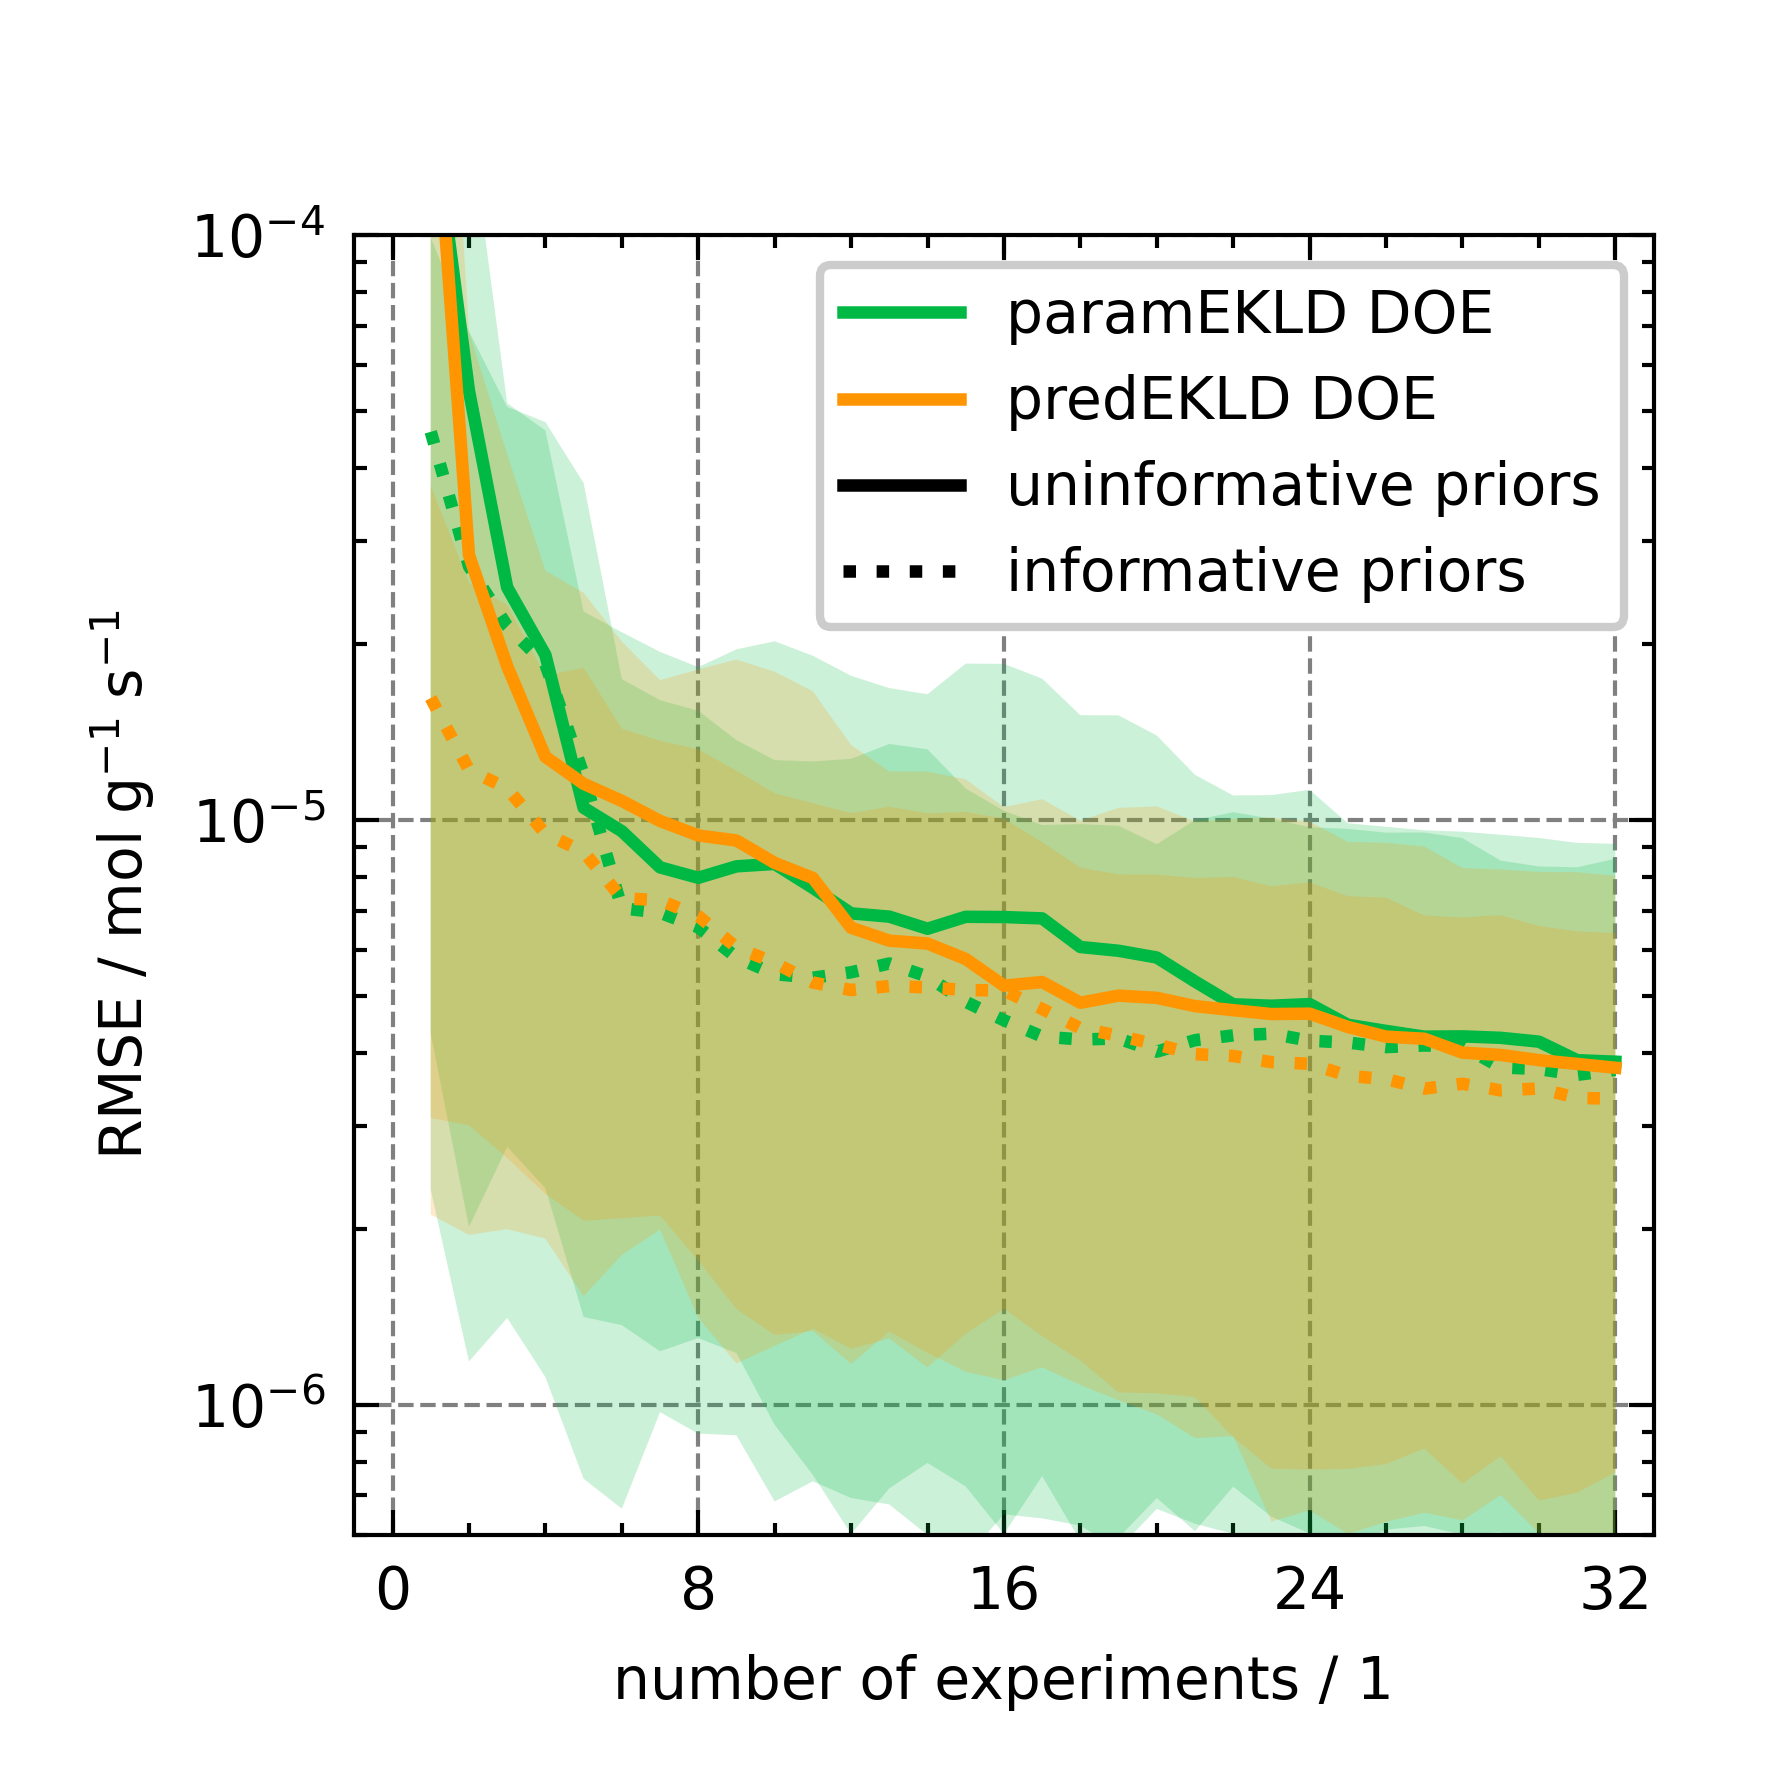

In [24]:
fig = ICIW_Plots.figure()
ax = ICIW_Plots.make_square_ax(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    xlabel="number of experiments / 1",
    ylabel=r"RMSE / $\mathrm{mol}\;\mathrm{g}^{-1}\;\mathrm{s}^{-1}$",
    yscale="log",
    ylim=(6e-7, 1e-4),
    xlim=(-1, 33),
    xticks=[0, 8, 16, 24, 32],
    left_h=1.5 * ICIW_Plots.cm2inch,
)

colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
for i, ov_dict in enumerate(ov):
    RMSEs = np.concatenate([ov_dict["RMSEs"][seed] for seed in ov_dict["seeds"]], axis=-1)
    if ov_dict["DOE"] in ["Koschany DOE", "LHS32 DOE", "LHS64 DOE"]:
        print(ov_dict["DOE"])
        xmax = len(ov_dict["RMSEs"][seed])
        ax.hlines(
            np.mean(RMSEs, axis=1)[-1],
            xmin=-1,
            xmax=xmax,
            label=ov_dict["DOE"],
            ls="--",
            color=colors[i],
        )
        HDI = az.hdi(RMSEs, prob=0.95, dim=0,)
        print(HDI.shape)
        ax.fill_between(
            np.arange(-1, RMSEs.shape[0] + 1),
            HDI[-1,0],
            HDI[-1,1],
            alpha=0.2,
            # ls="--",
            facecolor=colors[i],
            # edgecolor="gray",
        )
        continue
    ax.plot(
        np.arange(1, RMSEs.shape[0] + 1),
        np.mean(RMSEs, axis=1),
        # "o--",
        # ms=4,
        # lw=1,
        label=ov_dict["DOE"],
        **ov_dict["plot_kwargs"],
    )
    HDI = az.hdi(RMSEs, prob=0.95)
    ax.fill_between(
        np.arange(1, RMSEs.shape[0] + 1),
        HDI[:, 0],
        HDI[:, 1],
        alpha=0.2,
        # ls="--",
        facecolor=ov_dict["plot_kwargs"]["color"],
        # edgecolor="gray",
    )
ax.legend(
    handles=[
        plt.Line2D([], [], color=colors[1], ls="-", label="paramEKLD DOE"),
        plt.Line2D([], [], color=colors[2], ls="-", label="predEKLD DOE"),
        plt.Line2D([], [], color="k", ls="-", label="uninformative priors"),
        plt.Line2D([], [], color="k", ls="dotted", label="informative priors"),
    ],
    frameon=True,
)

plt.savefig("figures/rev/KinFit_RMSE_inf_priors.png", dpi=600)
plt.savefig("figures/rev/KinFit_RMSE_inf_priors.pdf")
plt.savefig("figures/rev/KinFit_RMSE_inf_priors.svg")

(32, 2)
(32, 2)
(32, 2)
(32, 2)
(32, 2)
(32, 2)
(32, 2)
(32, 2)
(32, 2)
(32, 2)
(32, 2)
(32, 2)
(32, 2)
(32, 2)
(32, 2)
(32, 2)
(32, 2)
(32, 2)
(32, 2)
(32, 2)


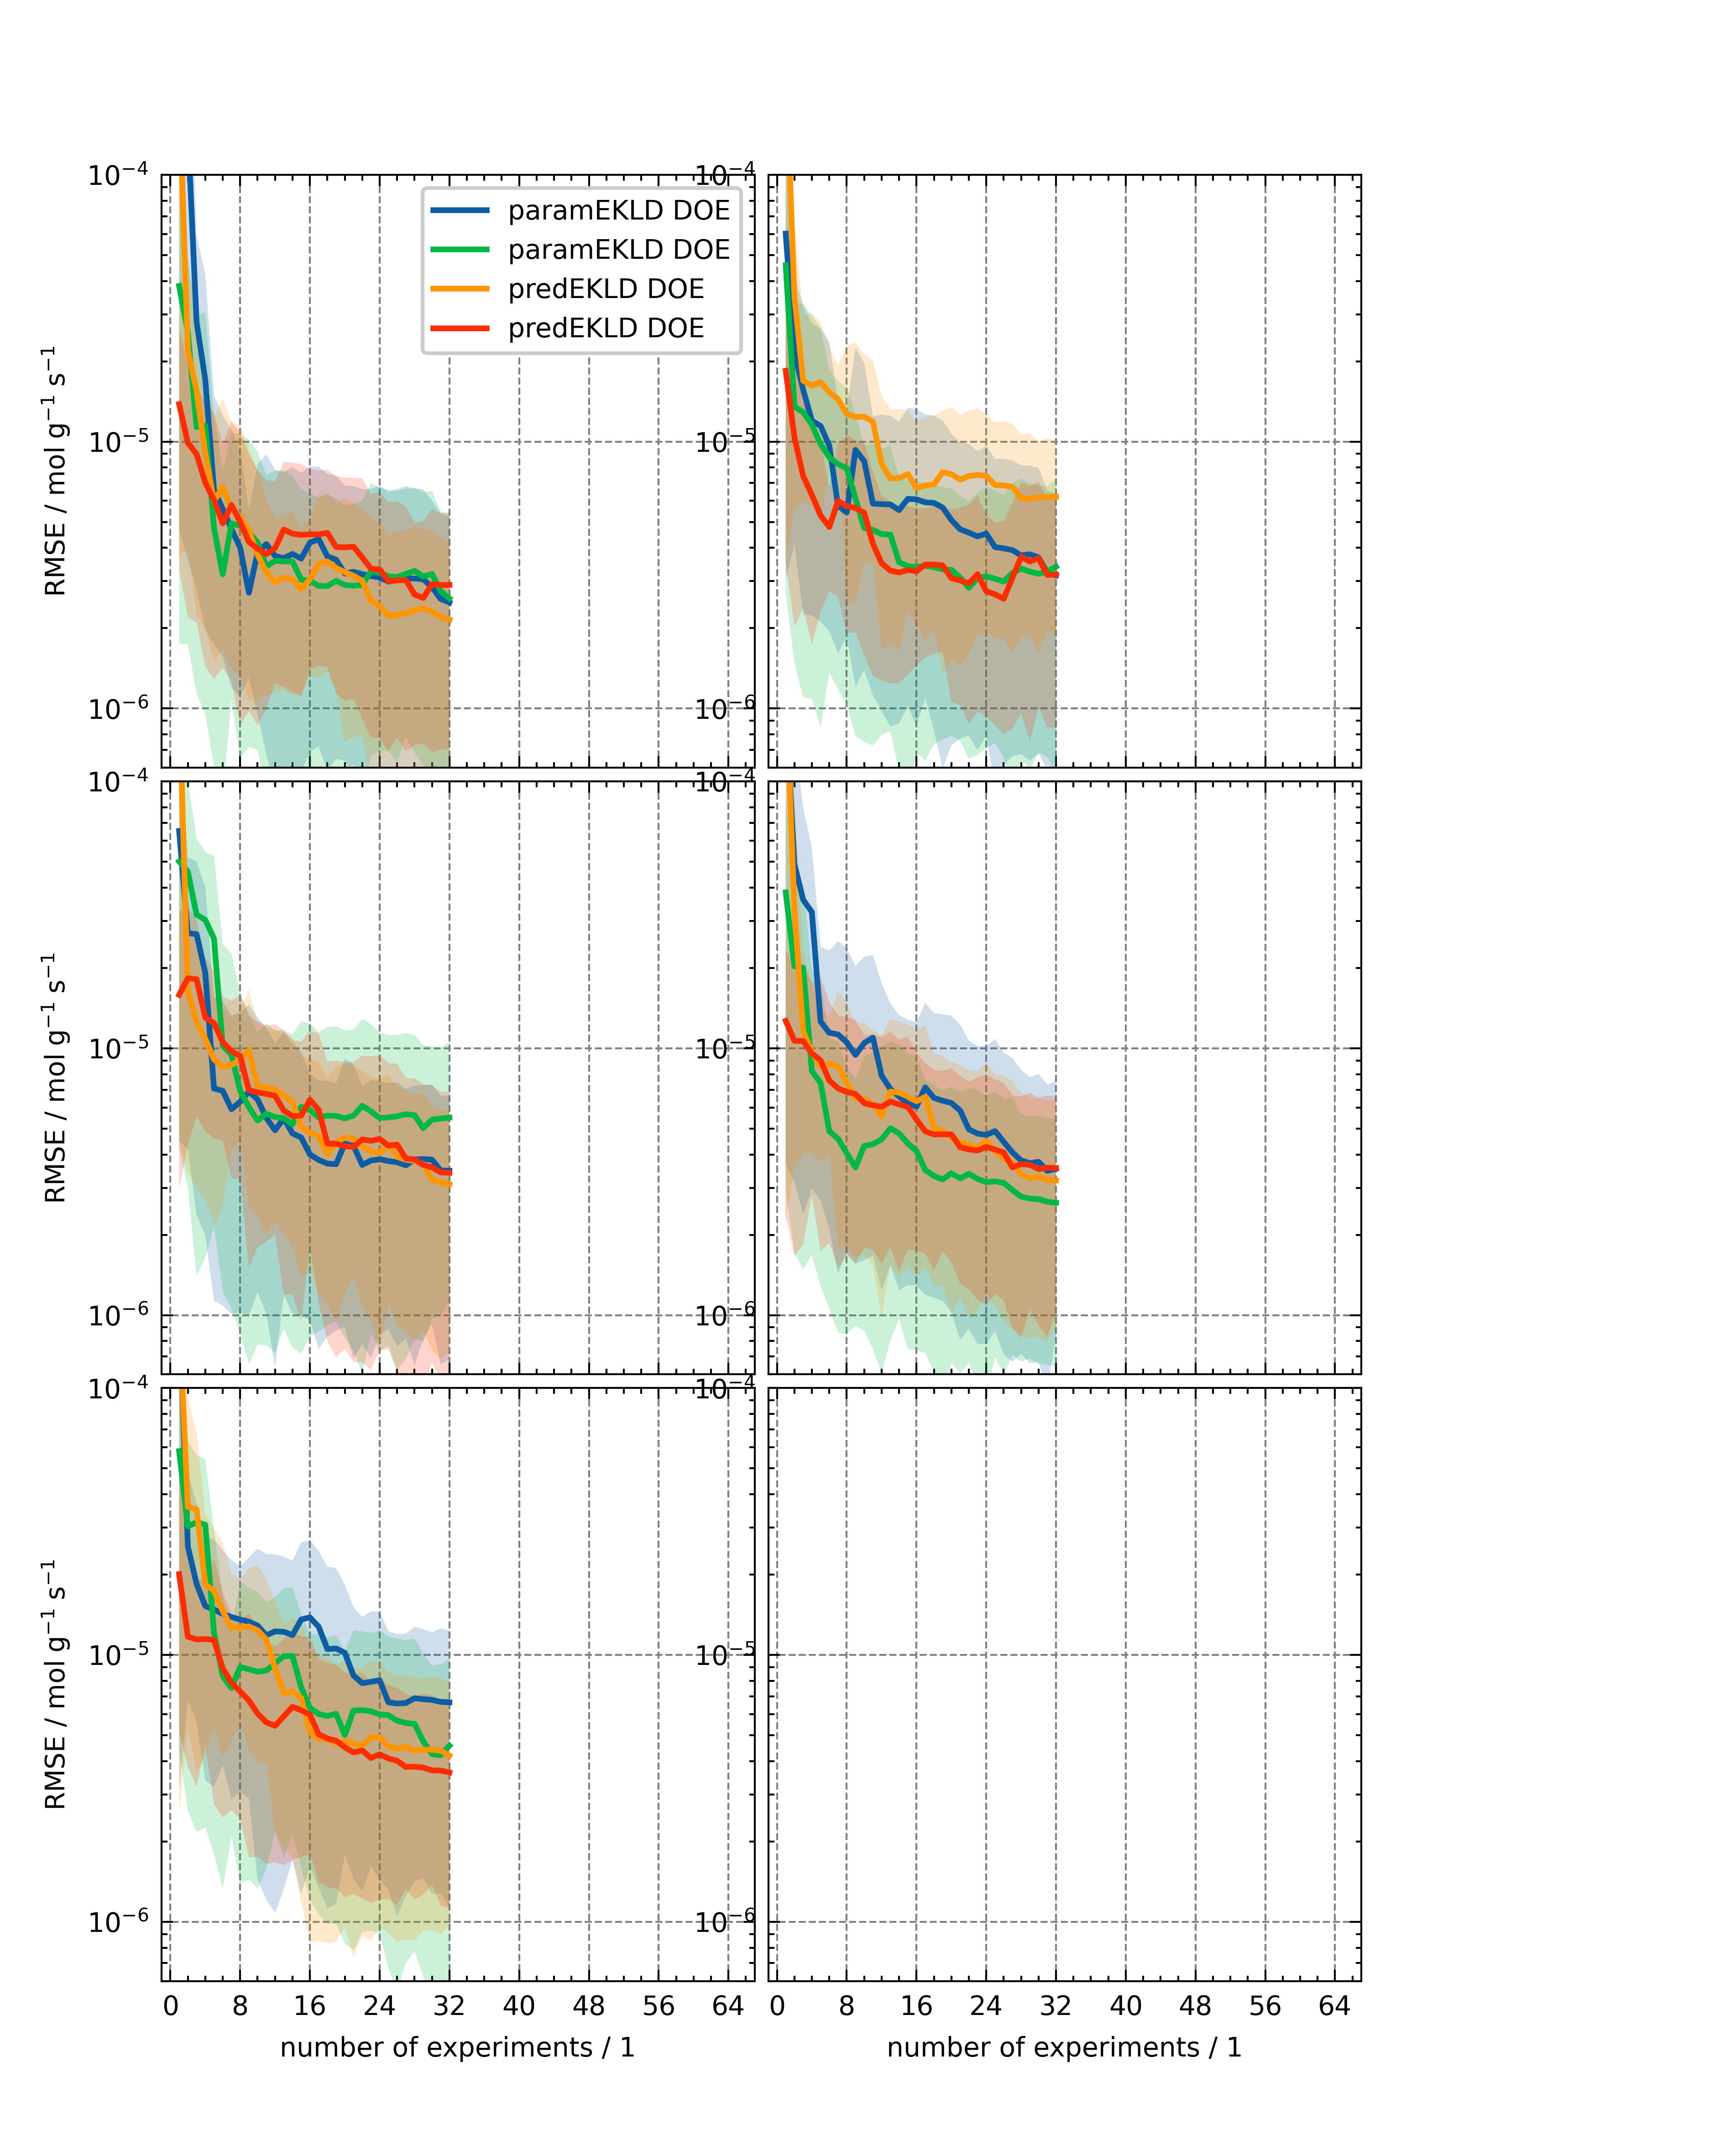

In [13]:
fig = ICIW_Plots.figure(layout="double_column", height=20*ICIW_Plots.cm2inch)
axs = ICIW_Plots.make_square_subplots(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    ax_layout=(3,2),
    xlabel="number of experiments / 1",
    ylabel=r"RMSE / $\mathrm{mol}\;\mathrm{g}^{-1}\;\mathrm{s}^{-1}$",
    yscale="log",
    sharex=True,
    sharey=True,
    ylim=(6e-7, 1e-4),
    xlim=(-1, 67),
    xticks=[0, 8, 16, 24, 32, 40, 48, 56, 64],
    left_h=1.5 * ICIW_Plots.cm2inch,
)
axs = axs.flatten()

colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
for i, ov_dict in enumerate(ov):
    for seed_idx, seed in enumerate(ov_dict["seeds"]):

        if ov_dict["DOE"] in ["Koschany DOE", "LHS32 DOE", "LHS64 DOE"]:
            xmax = len(ov_dict["RMSEs"][seed])
            axs[seed_idx].hlines(
                np.mean(ov_dict["RMSEs"][seed], axis=1)[-1],
                xmin=-1,
                xmax=xmax,
                label=ov_dict["DOE"],
                ls="--",
                color=colors[i],
            )
            HDI = az.hdi(ov_dict["RMSEs"][seed][-1], prob=0.95)
            axs[seed_idx].fill_between(
                np.arange(-1, len(ov_dict["RMSEs"][seed]) + 1),
                HDI[0],
                HDI[1],
                alpha=0.2,
                # ls="--",
                facecolor=colors[i],
                # edgecolor="gray",
            )
            continue
        axs[seed_idx].plot(
            np.arange(1, len(ov_dict["RMSEs"][seed]) + 1),
            np.mean(ov_dict["RMSEs"][seed], axis=1),
            # "o--",
            # ms=4,
            # lw=1,
            label=ov_dict["DOE"],
            color=colors[i],
        )
        HDI = az.hdi(ov_dict["RMSEs"][seed], prob=0.95)
        print(HDI.shape)
        axs[seed_idx].fill_between(
            np.arange(1, len(ov_dict["RMSEs"][seed]) + 1),
            HDI[:, 0],
            HDI[:, 1],
            alpha=0.2,
            # ls="--",
            facecolor=colors[i],
            # edgecolor="gray",
        )
    axs[0].legend(frameon=True)

### Information Gain

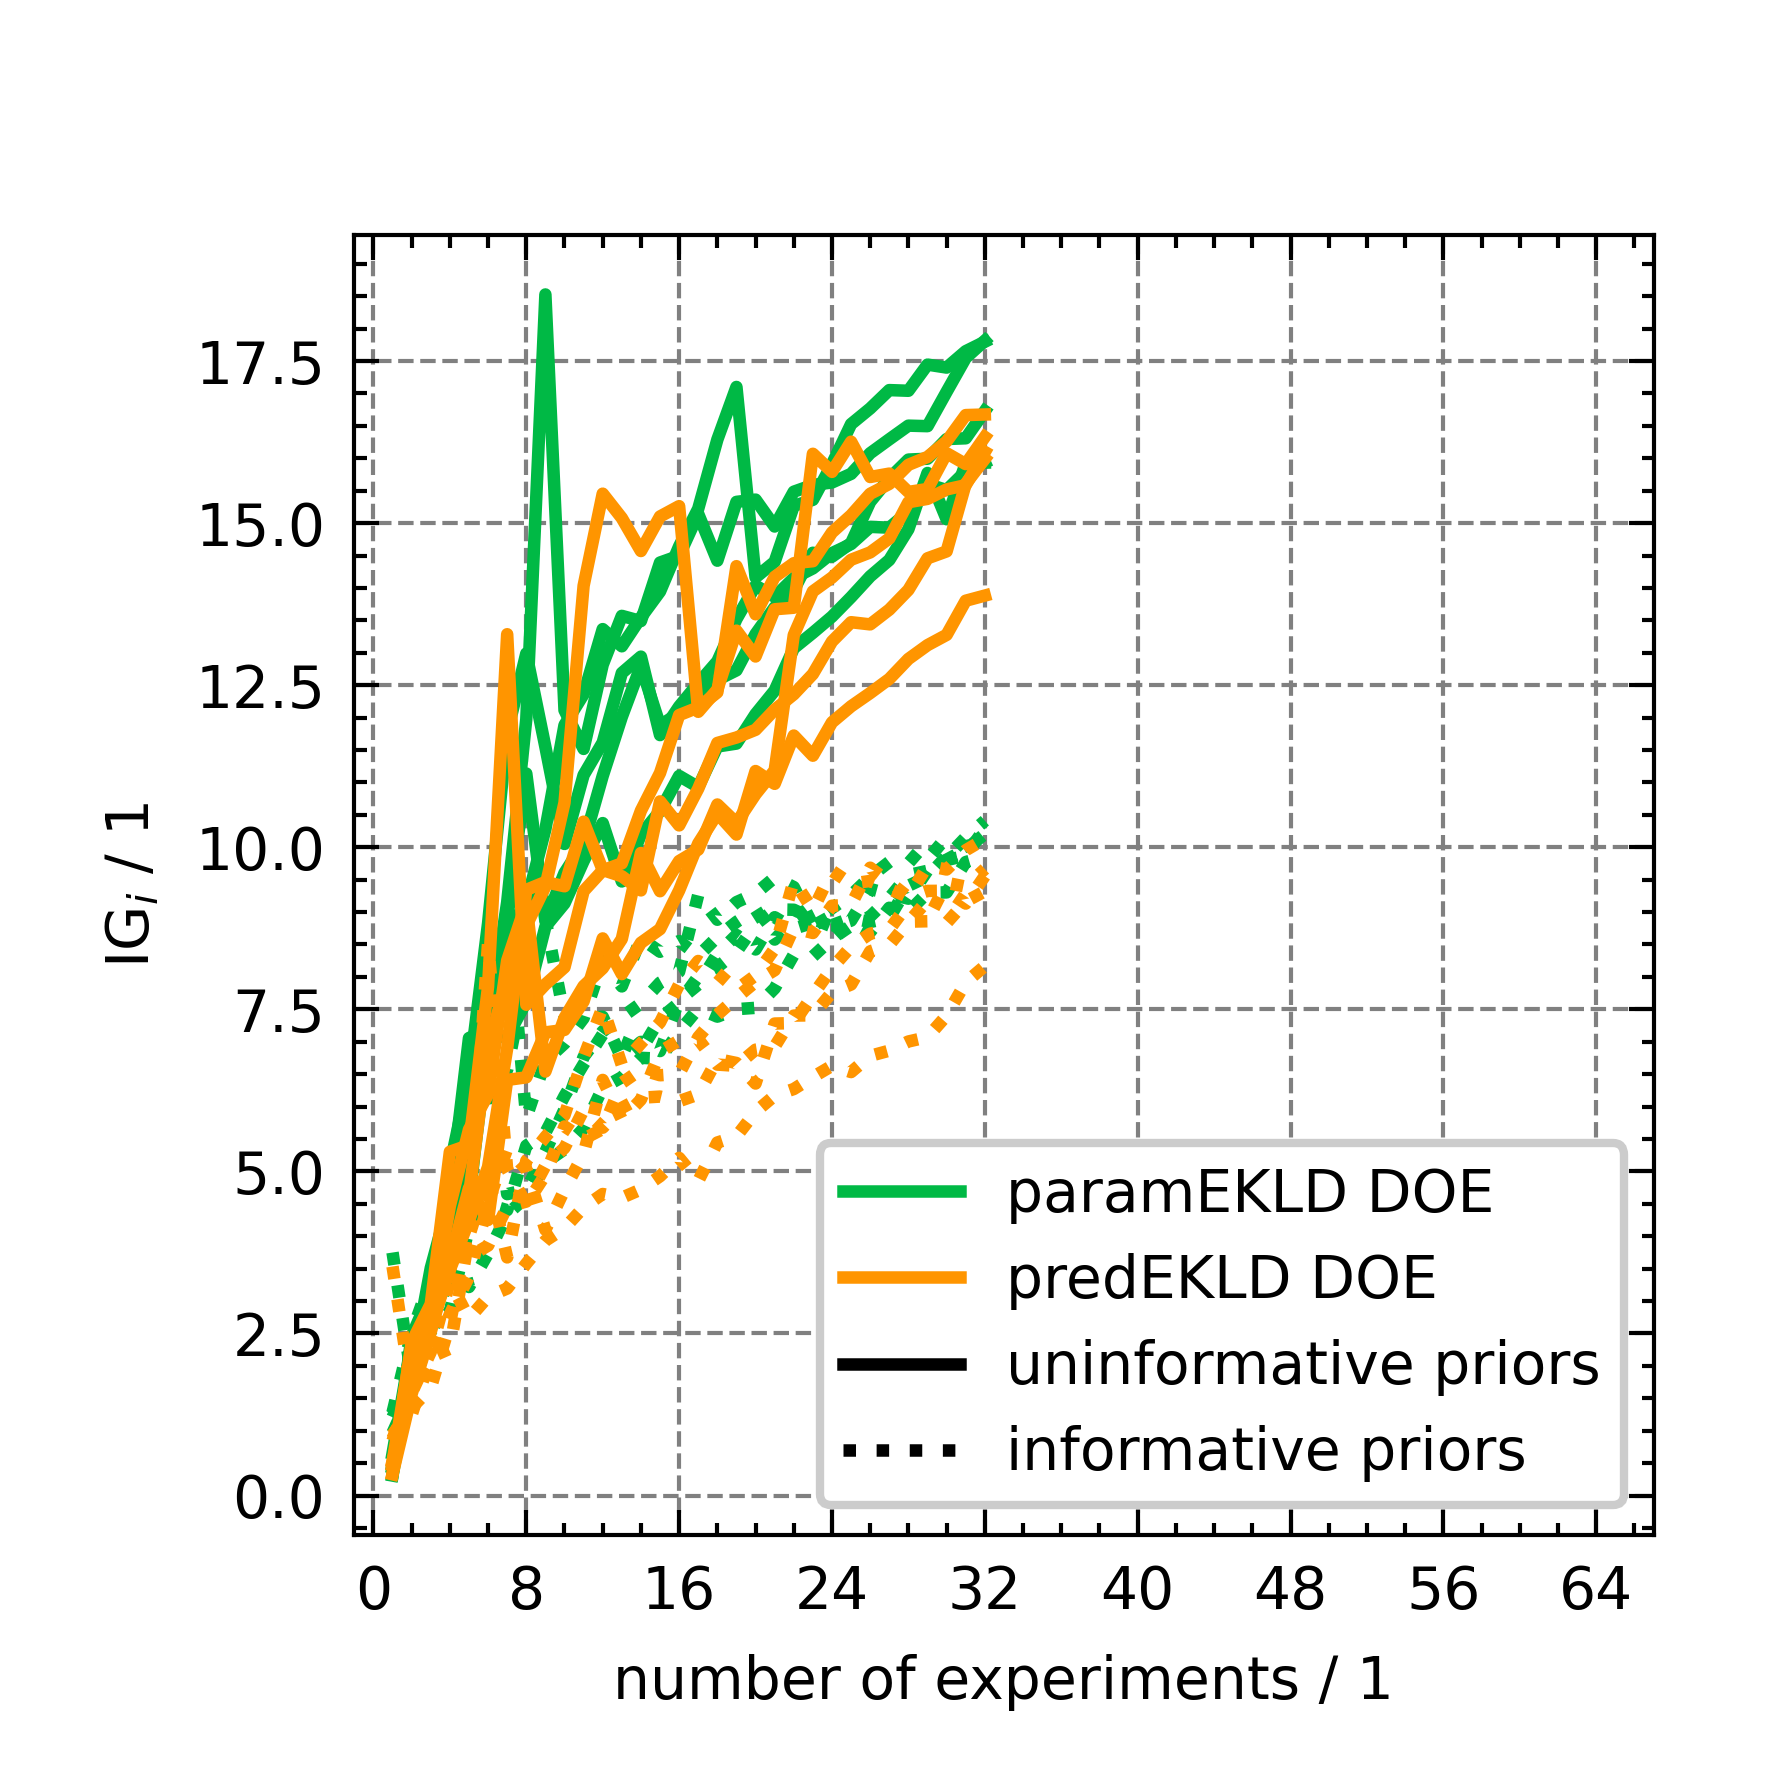

In [14]:
fig = ICIW_Plots.figure()
ax = ICIW_Plots.make_square_ax(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    xlabel="number of experiments / 1",
    ylabel=r"$\mathrm{IG}_i$ / 1",
    # ylim=(6e-7, 1e-4),
    xlim=(-1, 67),
    xticks=[0, 8, 16, 24, 32, 40, 48, 56, 64],
    left_h=1.5 * ICIW_Plots.cm2inch,
)
for i, ov_dict in enumerate(ov):
    for seed_idx, seed in enumerate(ov_dict["seeds"]):
        label = ov_dict["DOE"] if seed_idx == 0 else "_nolegend_"

        ax.plot(
            np.arange(len(ov_dict["paramEKLDS_to_prior"][seed])) + 1,
            ov_dict["paramEKLDS_to_prior"][seed],
            label=label,    
            **ov_dict["plot_kwargs"],
        )
ax.legend(
    handles=[
        plt.Line2D([], [], color=colors[1], ls="-", label="paramEKLD DOE"),
        plt.Line2D([], [], color=colors[2], ls="-", label="predEKLD DOE"),
        plt.Line2D([], [], color="k", ls="-", label="uninformative priors"),
        plt.Line2D([], [], color="k", ls="dotted", label="informative priors"),
    ],
    frameon=True,
)

plt.savefig("figures/rev/KinFit_IG_inf_priors.png")
plt.savefig("figures/rev/KinFit_IG_inf_priors.pdf")
plt.savefig("figures/rev/KinFit_IG_inf_priors.svg")

(32, 5)
(32, 5)
(32, 5)
(32, 5)


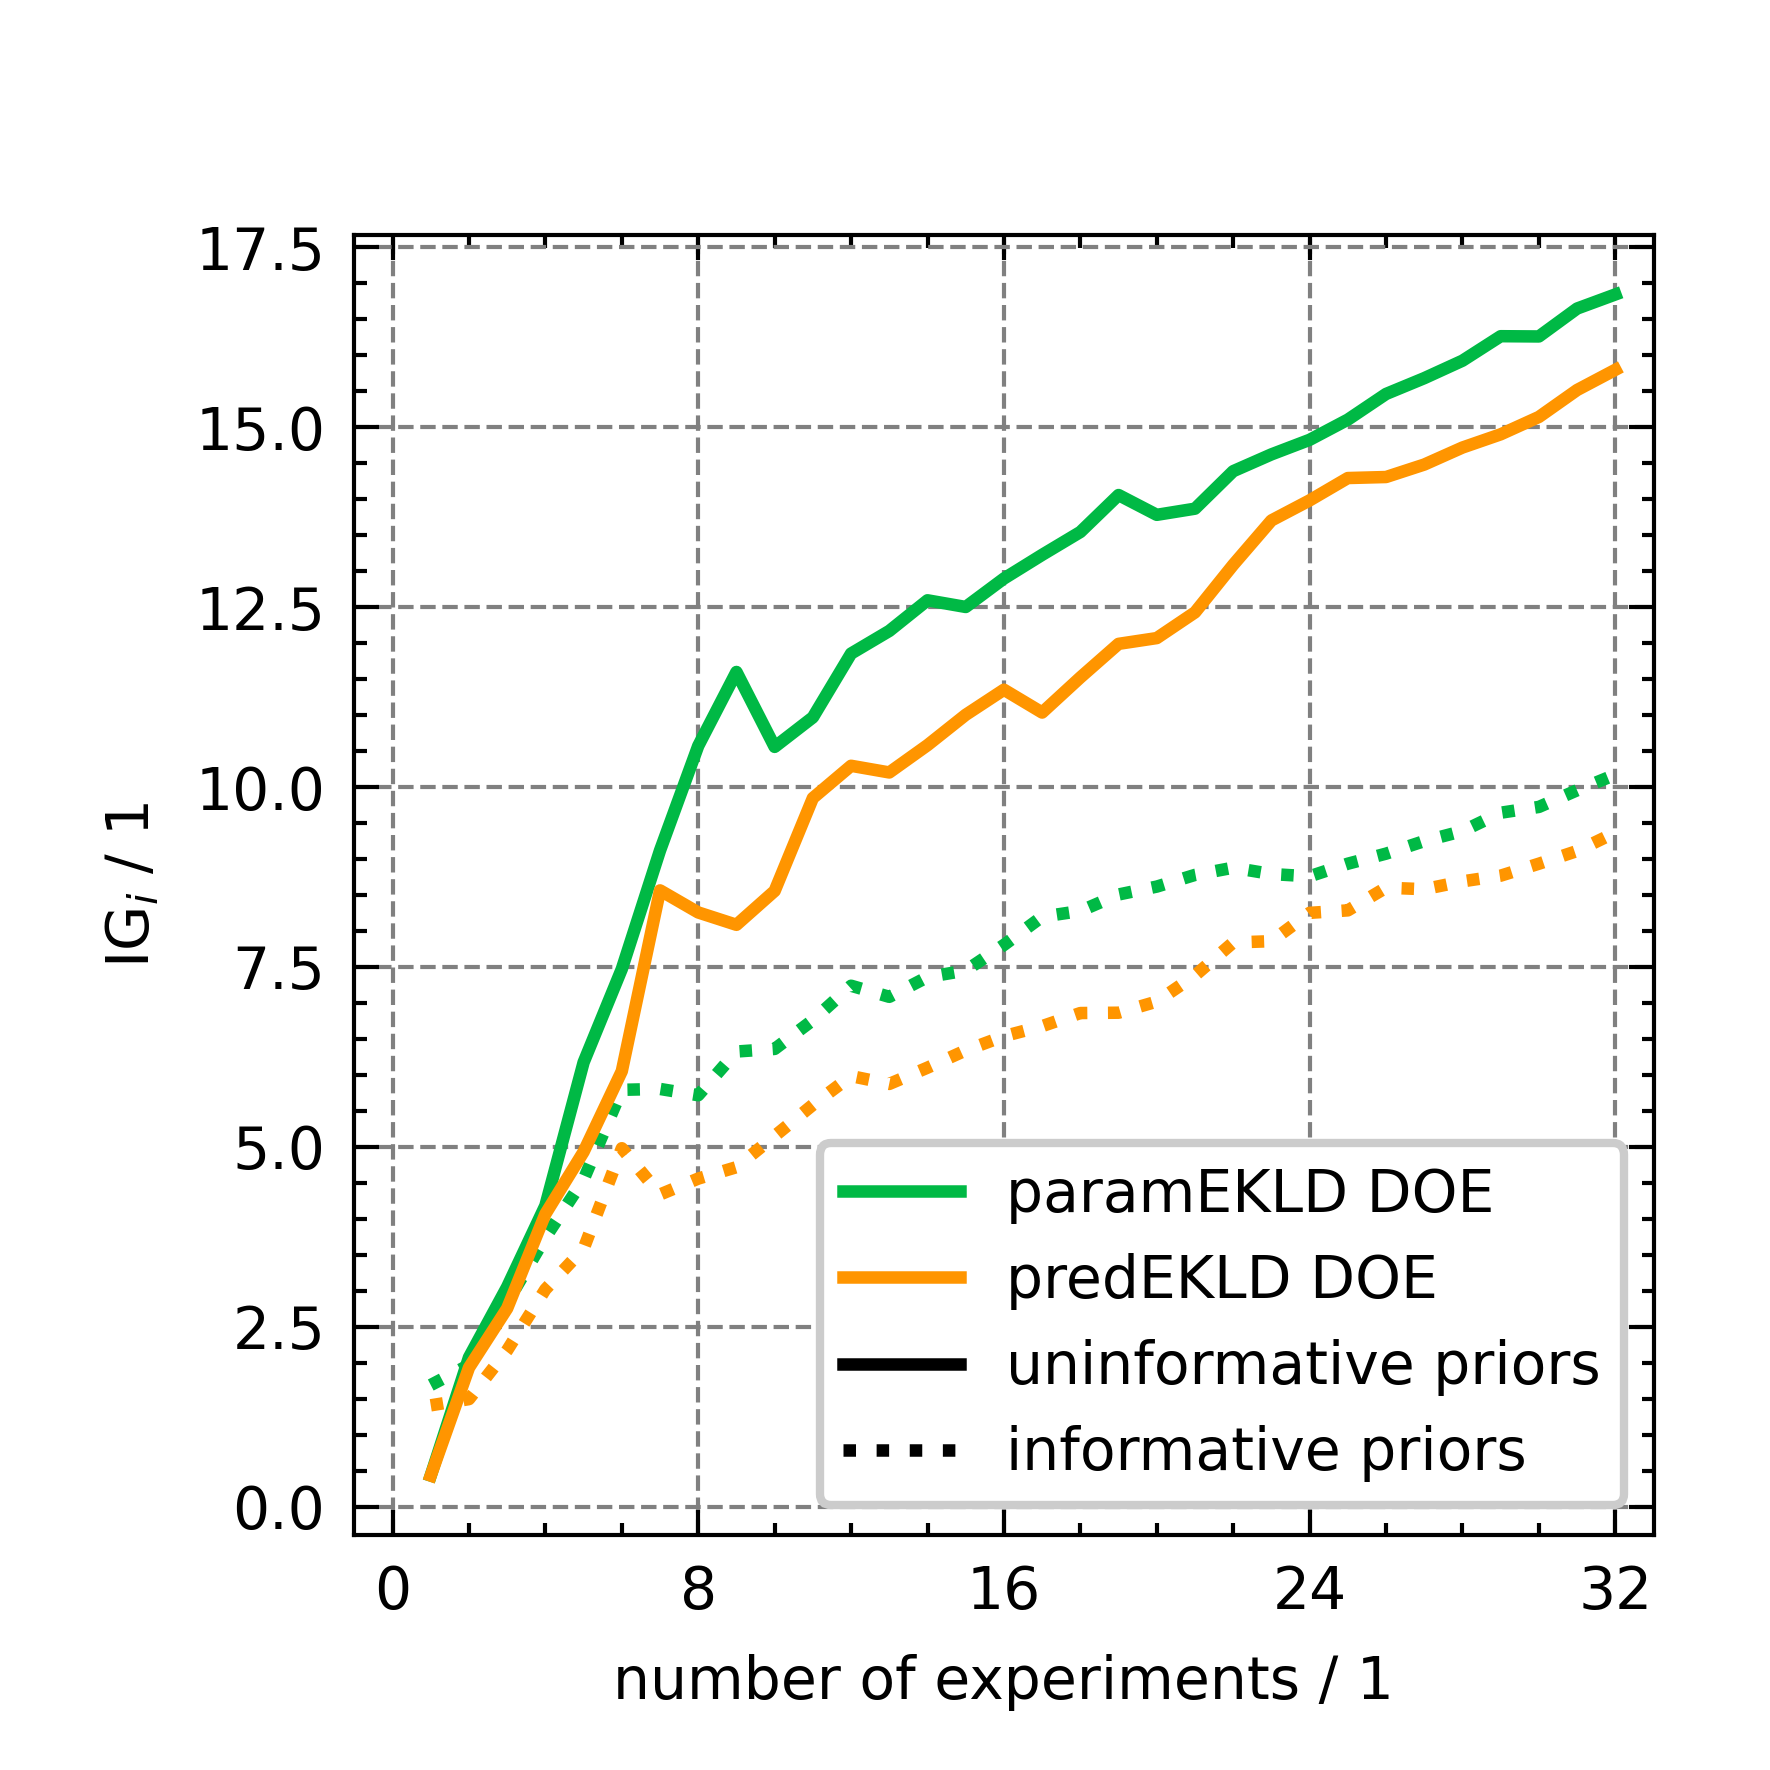

In [25]:
fig = ICIW_Plots.figure()
ax = ICIW_Plots.make_square_ax(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    xlabel="number of experiments / 1",
    ylabel=r"$\mathrm{IG}_i$ / 1",
    # ylim=(6e-7, 1e-4),
    xlim=(-1, 33),
    xticks=[0, 8, 16, 24, 32],
    left_h=1.5 * ICIW_Plots.cm2inch,
)
for i, ov_dict in enumerate(ov):
    IGs = np.stack([ov_dict["paramEKLDS_to_prior"][seed] for seed in ov_dict["seeds"]], axis=-1)
    print(IGs.shape)
    ax.plot(
        np.arange(IGs.shape[0]) + 1,
        IGs.mean(axis=1),
        label=ov_dict["DOE"],
        **ov_dict["plot_kwargs"],
        
    )
ax.legend(
    handles=[
        plt.Line2D([], [], color=colors[1], ls="-", label="paramEKLD DOE"),
        plt.Line2D([], [], color=colors[2], ls="-", label="predEKLD DOE"),
        plt.Line2D([], [], color="k", ls="-", label="uninformative priors"),
        plt.Line2D([], [], color="k", ls="dotted", label="informative priors"),
    ],
    frameon=True,
)

plt.savefig("figures/rev/KinFit_IG_inf_priors.png", dpi=600)
plt.savefig("figures/rev/KinFit_IG_inf_priors.pdf")
plt.savefig("figures/rev/KinFit_IG_inf_priors.svg")

### Parameter identified

In [16]:
def collect_param_samples_by_seed_and_step(ov_dict, key):
    """Return posterior samples with explicit seed and step dimensions."""
    per_seed = []
    for seed in ov_dict["seeds"]:
        per_step = []
        for step, idata in enumerate(ov_dict["idatas"][seed]):
            samples = idata.posterior[key].stack(sample=("chain", "draw")).values
            per_step.append(
                xarray.DataArray(
                    samples,
                    dims=("sample",),
                    coords={"sample": np.arange(samples.size)},
                ).expand_dims(step=[step])
            )
        per_seed.append(xarray.concat(per_step, dim="step").expand_dims(seed=[seed]))
    return xarray.concat(per_seed, dim="seed")


In [17]:
display(temp_data:=collect_param_samples_by_seed_and_step(ov[0], "k0"))
az.mean(temp_data, dim=("sample", "seed")).shape

<xarray.DataArray (seed: 5, step: 32, sample: 32000)> Size: 20MB
array([[[3.92467366e-04, 2.99362204e-04, 4.70289408e-04, ...,
         1.17832824e-04, 2.29586978e-04, 1.41585001e-03],
        [3.75898671e-04, 1.07003073e-03, 2.62875576e-04, ...,
         1.18113079e-04, 2.61192035e-04, 1.41739682e-03],
        [2.83967500e-04, 4.05934203e-04, 7.98743917e-04, ...,
         2.24515345e-04, 9.28964932e-04, 3.16205784e-04],
        ...,
        [4.02524427e-04, 4.12532827e-04, 4.06690000e-04, ...,
         4.10206034e-04, 4.01700730e-04, 3.47633031e-04],
        [3.97770025e-04, 4.08203865e-04, 4.03346581e-04, ...,
         4.06158972e-04, 3.77744029e-04, 3.36765137e-04],
        [3.97773430e-04, 4.07444080e-04, 4.02736594e-04, ...,
         4.09819884e-04, 3.78059718e-04, 3.40689498e-04]],

       [[6.76591531e-04, 1.21663767e-03, 4.57680959e-04, ...,
         1.50940337e-04, 1.37651397e-03, 1.40964566e-03],
        [5.02303126e-04, 9.32205992e-04, 1.46138540e-04, ...,
         7.36203801e-04, 7.43671379e-04, 6.40809769e-04],
        [1.60757918e-03, 1.30343693e-03, 7.54194101e-04, ...,
         3.53856361e-04, 3.86011845e-04, 1.65468873e-03],
...
         4.18286043e-04, 3.78101919e-04, 3.26173234e-04],
        [4.04789520e-04, 4.17022442e-04, 4.10235574e-04, ...,
         4.17414529e-04, 3.79293546e-04, 3.27900460e-04],
        [3.78175668e-04, 3.96923657e-04, 4.00346471e-04, ...,
         4.22617333e-04, 3.84520856e-04, 3.34621320e-04]],

       [[3.22769425e-04, 2.47199234e-04, 1.06713807e-04, ...,
         2.38233246e-04, 2.42919457e-04, 2.42919457e-04],
        [5.46739786e-04, 4.81087889e-04, 2.88820564e-04, ...,
         1.34666247e-04, 1.41833327e-04, 2.25958065e-03],
        [2.20084024e-04, 2.29765283e-04, 2.74475839e-04, ...,
         7.10808265e-04, 6.80246332e-04, 1.21857226e-03],
        ...,
        [3.41180625e-04, 3.57095909e-04, 3.61400860e-04, ...,
         3.78433615e-04, 3.42401676e-04, 3.00257700e-04],
        [3.81816411e-04, 3.91568610e-04, 3.80658952e-04, ...,
         3.67567118e-04, 3.31781164e-04, 2.88404117e-04],
        [3.55636876e-04, 3.66401509e-04, 3.60339473e-04, ...,
         3.64069885e-04, 3.32981872e-04, 2.90686352e-04]]],
      shape=(5, 32, 32000), dtype=float32)
Coordinates:
  * seed     (seed) int64 40B 43 44 45 46 47
  * step     (step) int64 256B 0 1 2 3 4 5 6 7 8 ... 23 24 25 26 27 28 29 30 31
  * sample   (sample) int64 256kB 0 1 2 3 4 5 ... 31995 31996 31997 31998 31999

(32,)

In [18]:
from ipywidgets import interact, Dropdown

keydict = {
    "k0": "k0",
    "Ea_k": "EA",
    "A_oh": "A_OH",
    "dH_oh": "H_OH",
    "A_h2": "A_H2",
    "dH_h2": "H_H2",
    "A_mix": "A_mix",
    "dH_mix": "H_mix",
}


@interact(
    key=Dropdown(
        options=keydict.keys(),
        value="k0",
        description="Parameter:",
    ),
)
def plot_parameter_evolution(key):
    fig = ICIW_Plots.figure()
    ax = ICIW_Plots.make_square_ax(
        fig,
        ax_width=5.5 * ICIW_Plots.cm2inch,
        xlabel="number of experiments / 1",
        ylabel=f"{keydict[key]} / units",
        yscale="log",
        # ylim=(6e-7, 1e-4),
        # xlim=(-1, 67),
        xticks=[0, 8, 16, 24, 32, 40, 48, 56, 64],
        left_h=1.5 * ICIW_Plots.cm2inch,
    )
    # ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
    for i, ov_dict in enumerate(ov):
        param_samples = collect_param_samples_by_seed_and_step(ov_dict, key)
        ax.axhline(
            y=TRUE_PARAMS[keydict[key]],
            color="gray",
            linestyle="dashed",
            zorder=0,
        )
        if ov_dict["DOE"] == "Koschany DOE":
            ax.hlines(
                param_samples.mean(dim=("sample", "seed"))[-1],
                xmin=-1,
                xmax=64,
                label=ov_dict["DOE"],
                ls="--",
                color=colors[i],
            )
            HDI = az.hdi(param_samples, prob=0.95, dim=("sample", "seed")).isel(step=-1)
            ax.fill_between(
                np.arange(-1, param_samples.sizes["step"] + 1),
                HDI[0],
                HDI[1],
                alpha=0.2,
                # ls="--",
                facecolor=colors[i],
                # edgecolor="gray",
            )
            continue
        ax.plot(
            np.arange(1, param_samples.sizes["step"] + 1),
            param_samples.mean(dim=("sample", "seed")),
            label=ov_dict["DOE"],
            color=plt.rcParams["axes.prop_cycle"].by_key()["color"][i],
        )
        HDI = az.hdi(param_samples, prob=0.95, dim=("sample", "seed"))
        ax.fill_between(
            np.arange(1, param_samples.sizes["step"] + 1),
            HDI[:, 0],
            HDI[:, 1],
            alpha=0.2,
            facecolor=plt.rcParams["axes.prop_cycle"].by_key()["color"][i],
        )
        ax.legend(frameon=True)

interactive(children=(Dropdown(description='Parameter:', options=('k0', 'Ea_k', 'A_oh', 'dH_oh', 'A_h2', 'dH_h…

(9e-05, 0.0015)

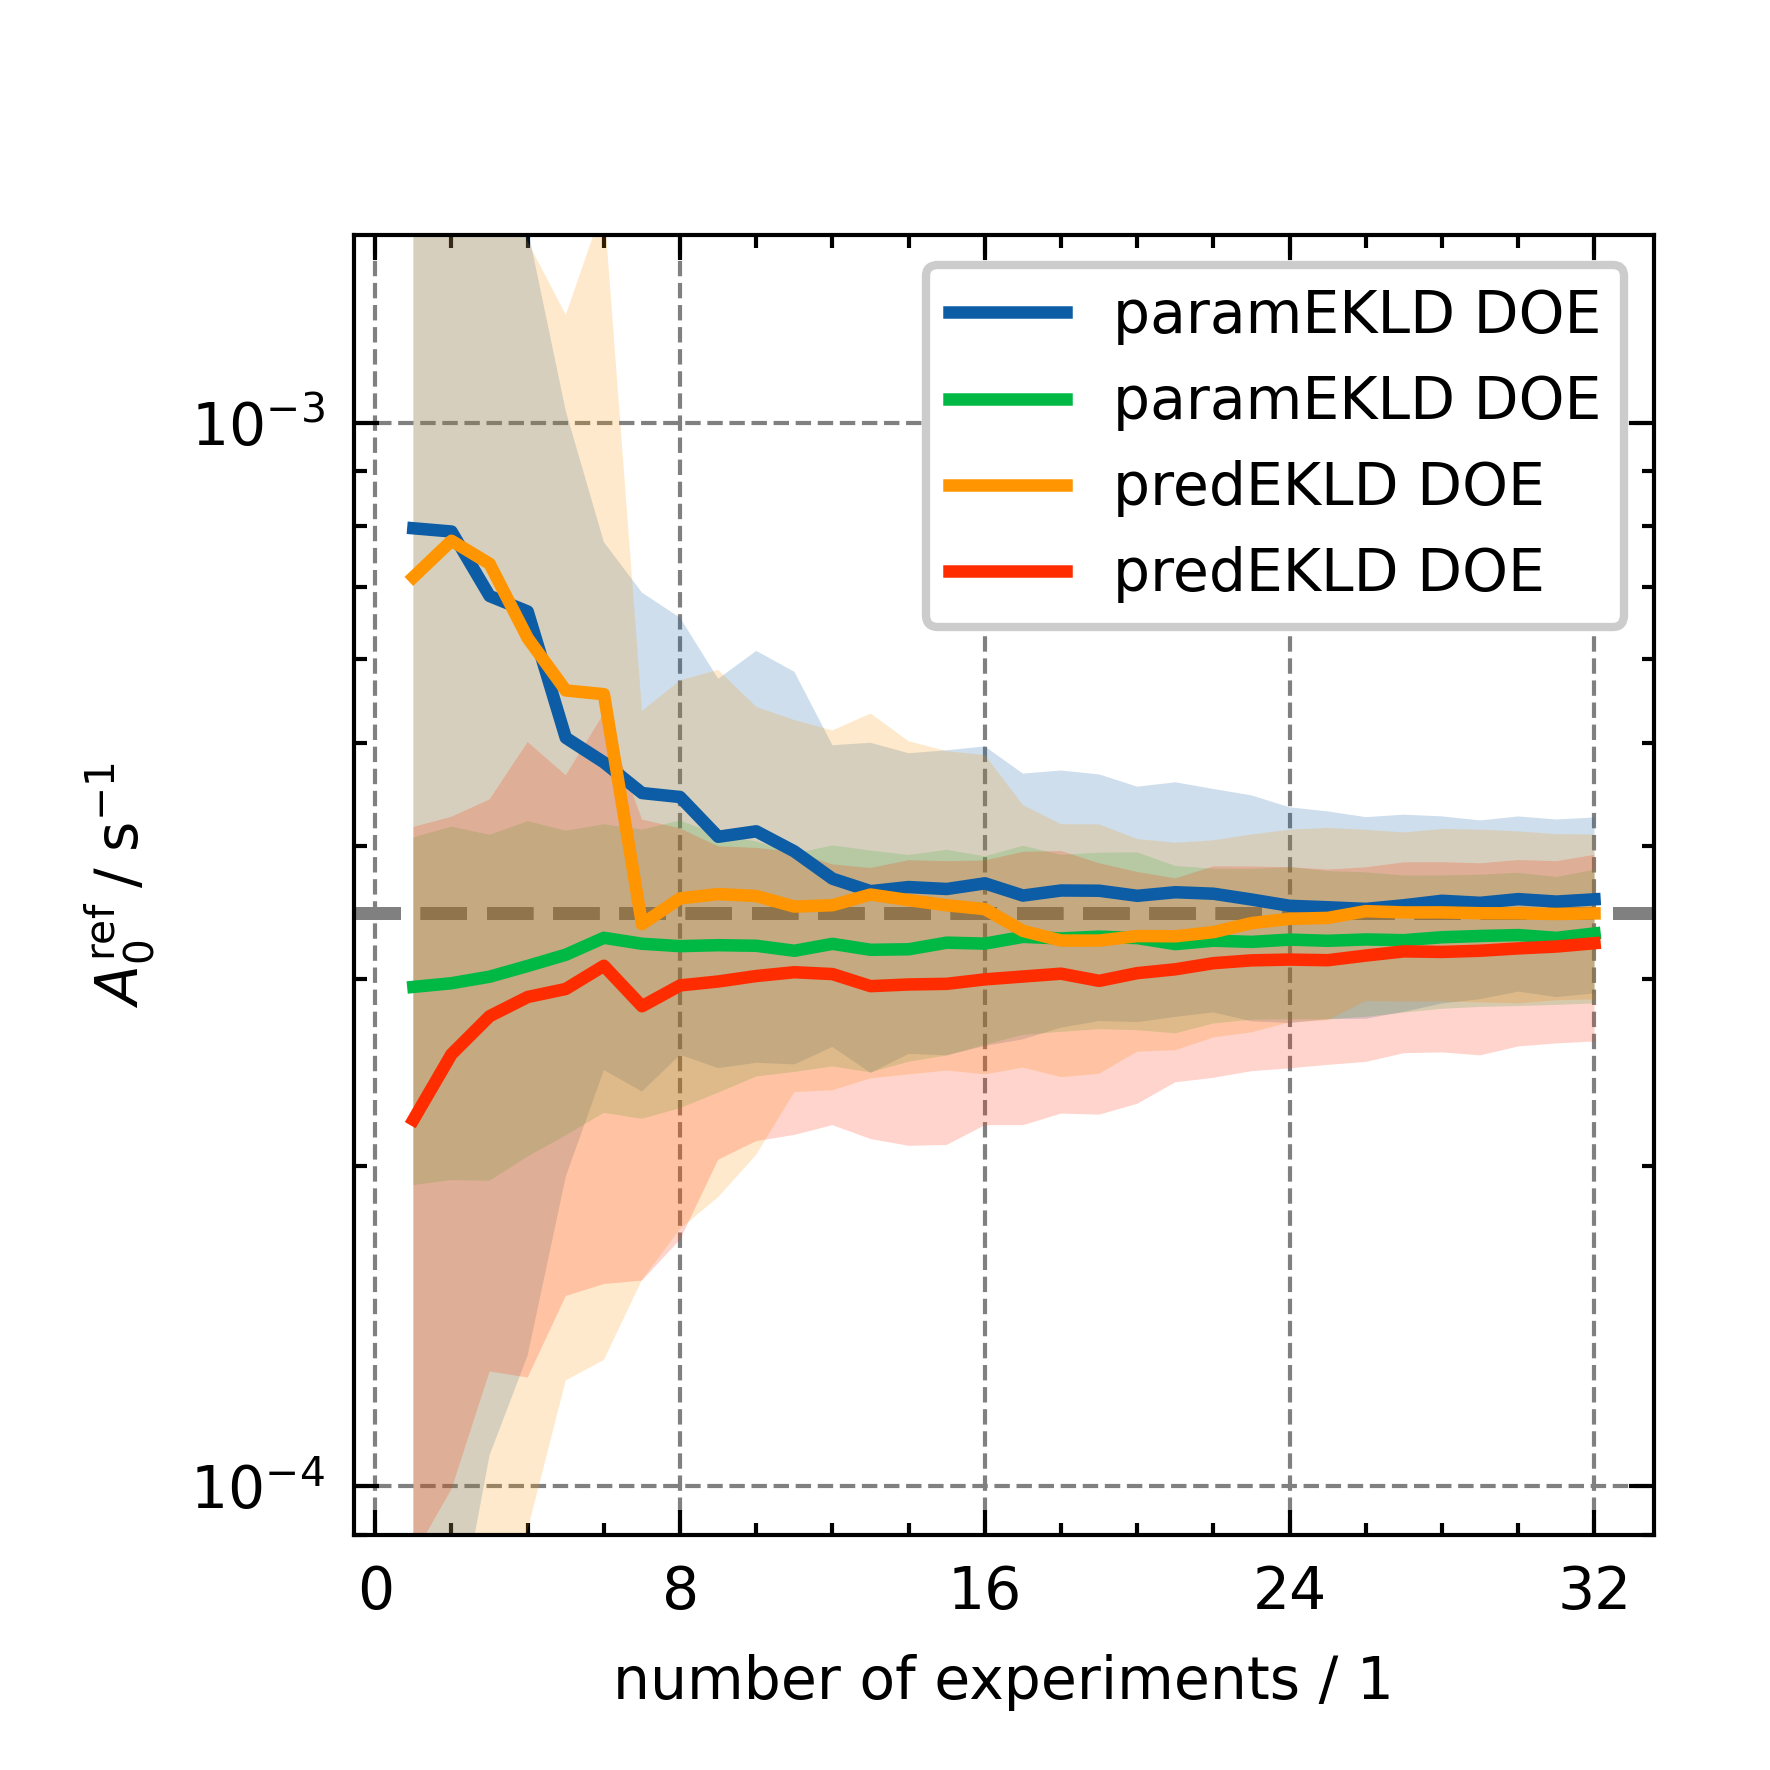

In [19]:
plot_parameter_evolution("k0")
ax = plt.gca()
ax.set_ylabel(r"$A_0^\mathrm{ref}\;/\; \mathrm{s}^{-1}$")
ax.set_ylim(9e-5, 1.5e-3)
# plt.savefig("figures/KinFit_k0_evolution.png")
# plt.savefig("figures/KinFit_k0_evolution.pdf")
# plt.savefig("figures/KinFit_k0_evolution.svg")

(60000.0, 90000.0)

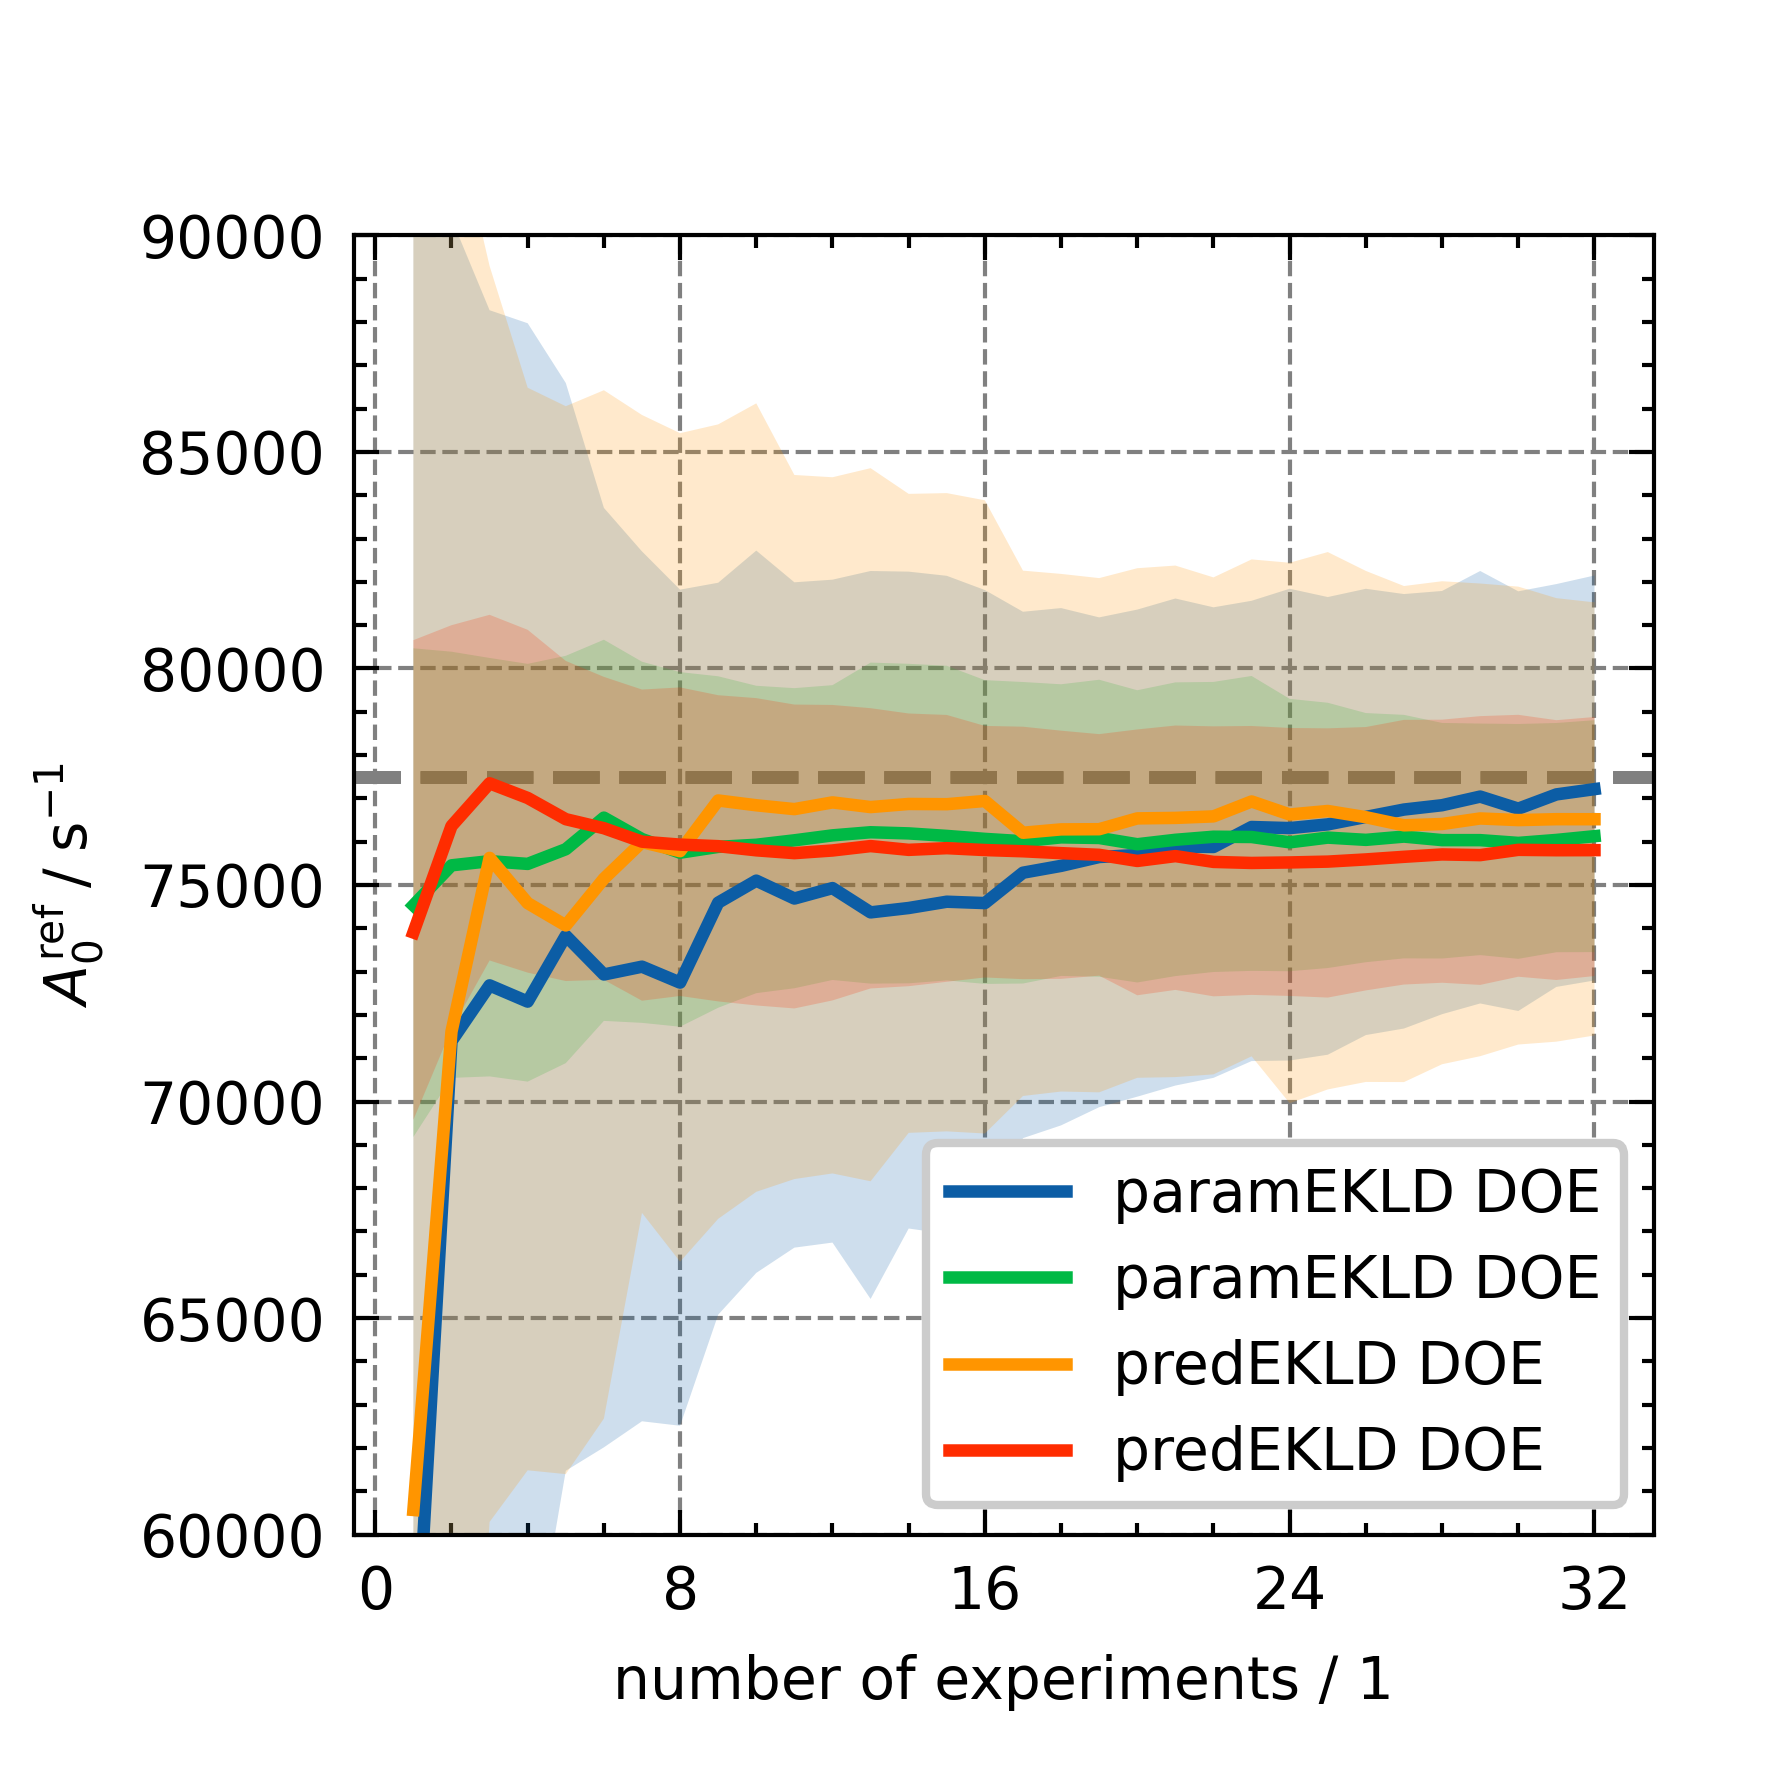

In [20]:
plot_parameter_evolution("Ea_k")
ax = plt.gca()
ax.set_yscale("linear")
ax.set_ylabel(r"$A_0^\mathrm{ref}\;/\; \mathrm{s}^{-1}$")
ax.set_ylim(60000, 90000)

## Parameter distributions

/home/hannes/Environments/.BIBOvenv/lib/python3.12/site-packages/ICIW_Plots/layout.py:468: UserWarning:

Unscientific behavior. No xlabel provided.

/home/hannes/Environments/.BIBOvenv/lib/python3.12/site-packages/ICIW_Plots/layout.py:503: UserWarning:

Unscientific behavior. No ylabel provided.



(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)


/tmp/ipykernel_95145/1621023765.py:123: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



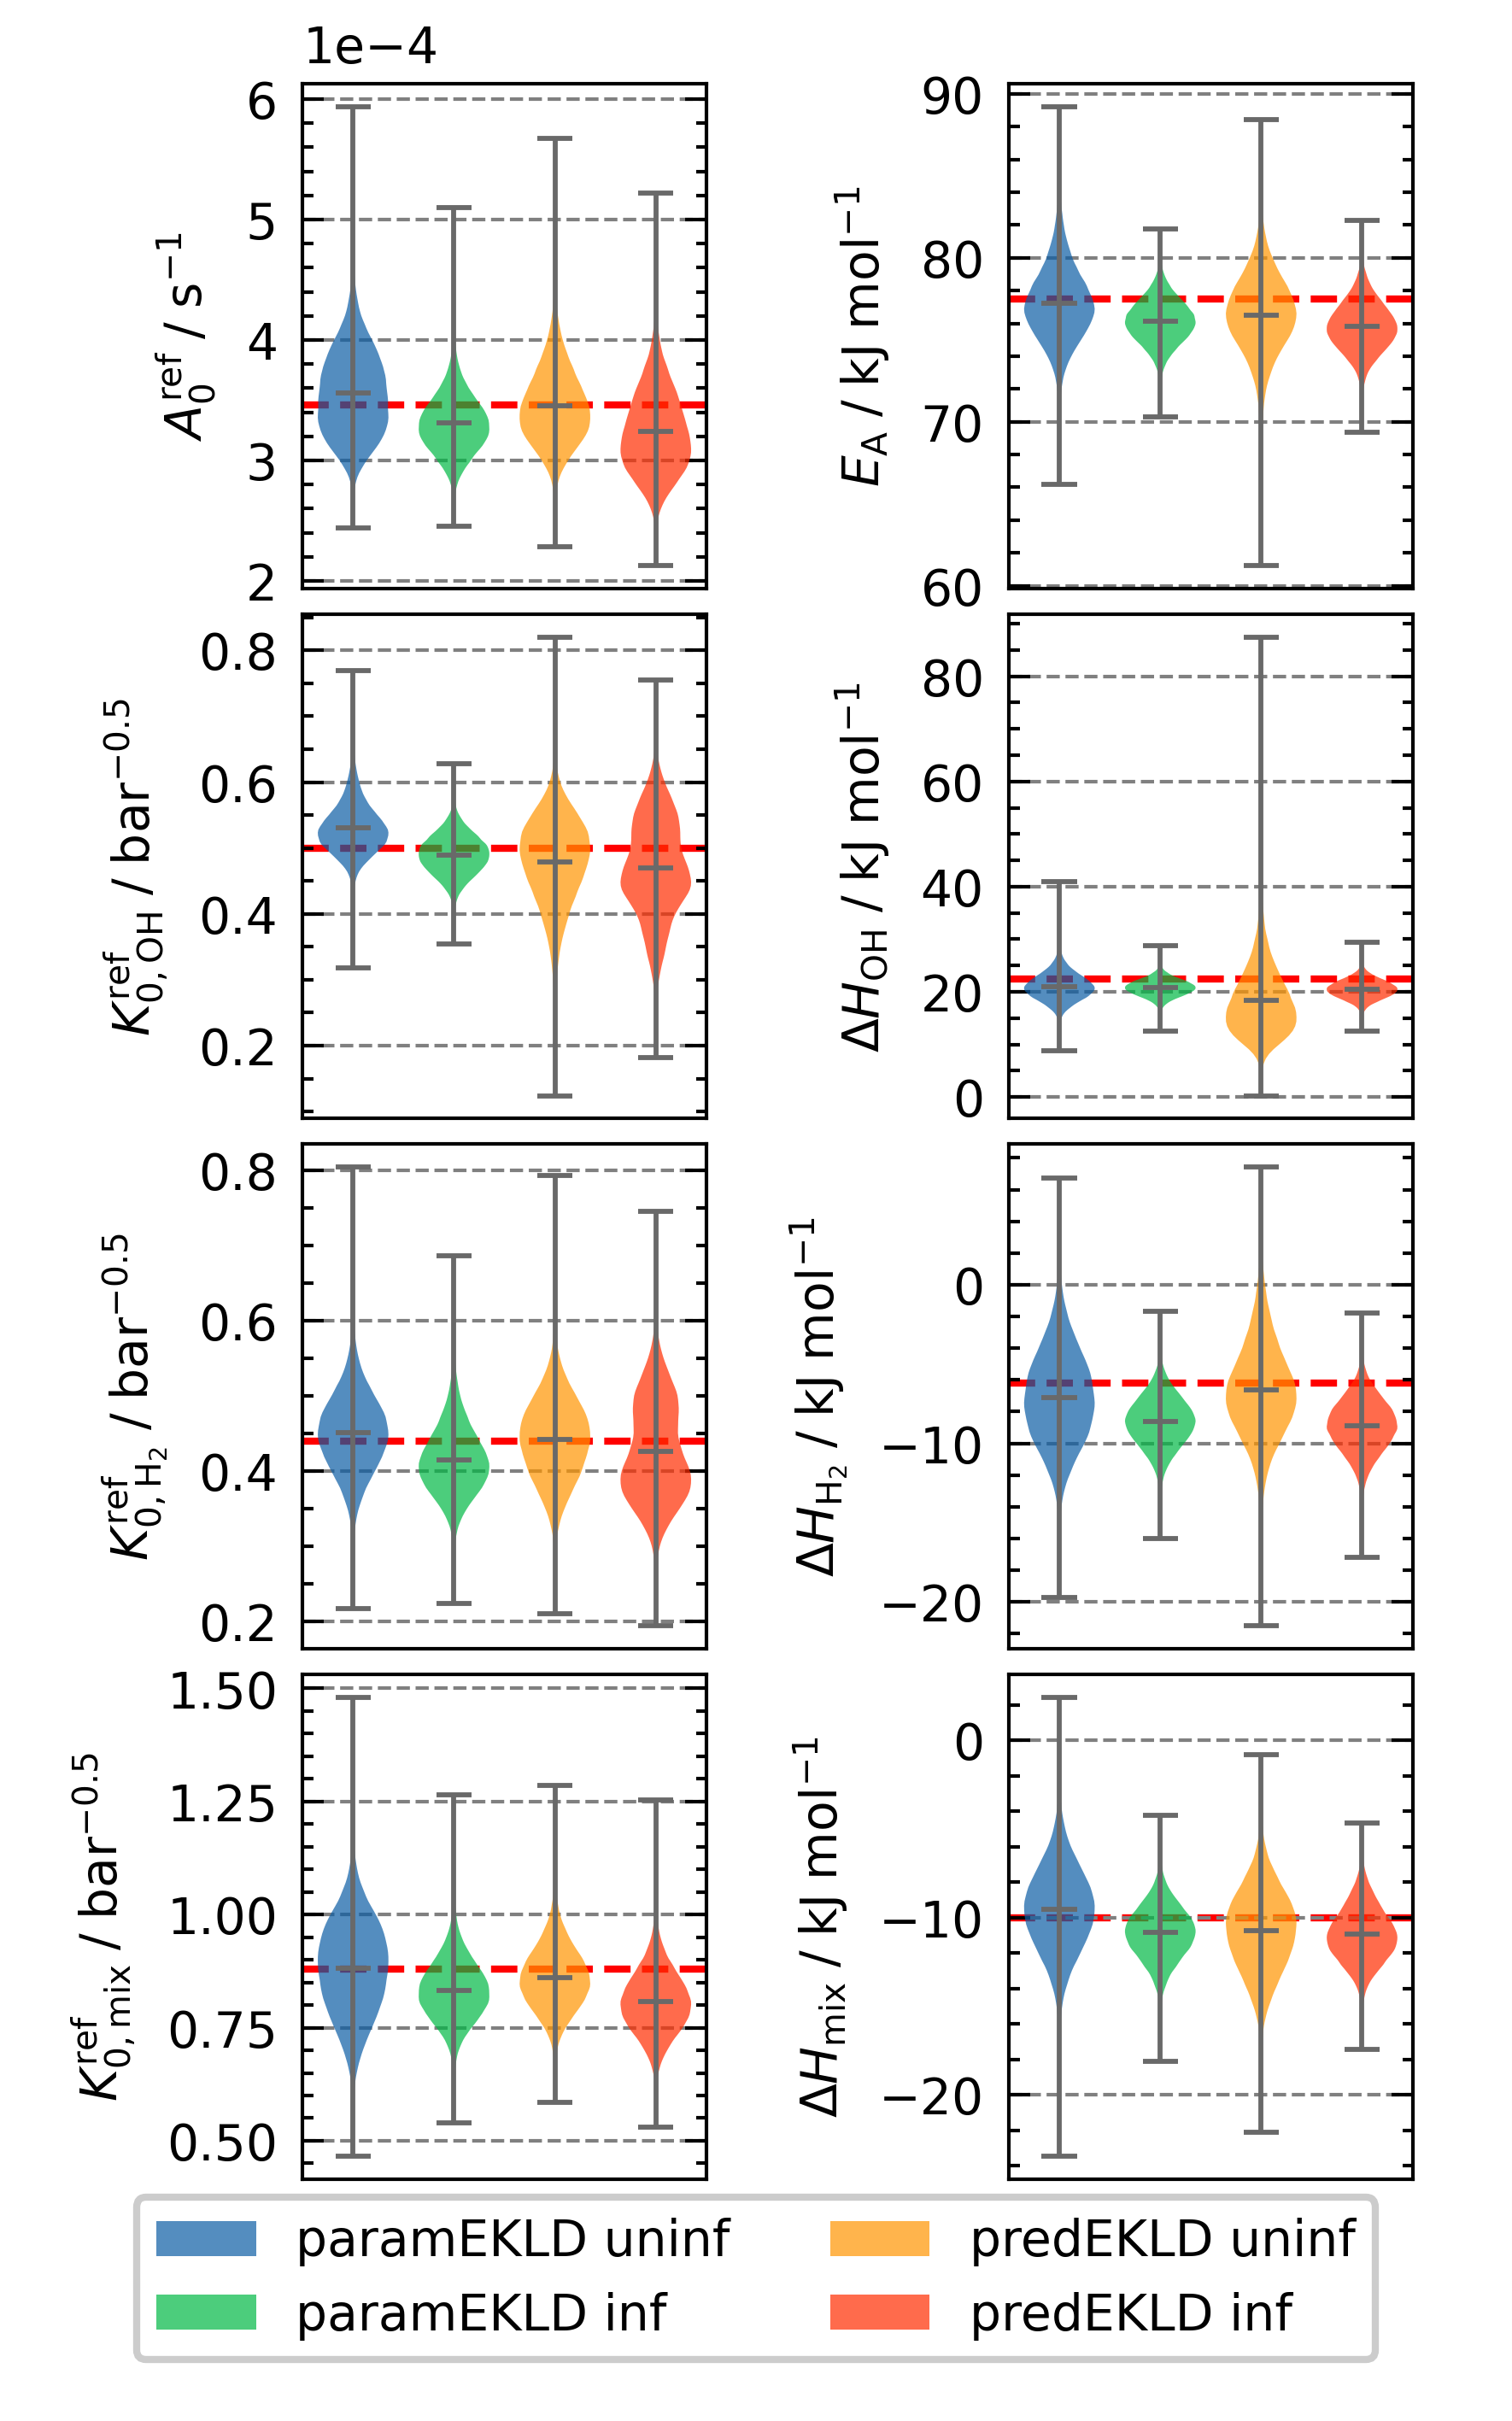

In [21]:
# fig, axes = plt.subplots(4, 2, figsize=(12, 16))
fig = ICIW_Plots.figure(layout="single_column", height=12 * ICIW_Plots.cm2inch)
axes = ICIW_Plots.make_rect_subplots(
    fig,
    ax_width=2.0 * ICIW_Plots.cm2inch,
    ax_layout=(4, 2),
    ax_height=2.5 * ICIW_Plots.cm2inch,
    h_sep=1.5 * ICIW_Plots.cm2inch,
    # sharex=True,
    left_h=1.5 * ICIW_Plots.cm2inch,
    bottom_v=1.2 * ICIW_Plots.cm2inch,
)
axes = axes.flatten()

param_names = ["k0", "Ea_k", "A_oh", "dH_oh", "A_h2", "dH_h2", "A_mix", "dH_mix"]

keydict = {
    "k0": "k0",
    "Ea_k": "EA",
    "A_oh": "A_OH",
    "dH_oh": "H_OH",
    "A_h2": "A_H2",
    "dH_h2": "H_H2",
    "A_mix": "A_mix",
    "dH_mix": "H_mix",
}
labeldict = {
    "k0": r"$A_0^\mathrm{ref}\;/\; \mathrm{s}^{-1}$",
    "Ea_k": r"$E_\mathrm{A}\;/\;\mathrm{kJ}\;\mathrm{mol}^{-1}$",
    "A_oh": r"$K_{0,\mathrm{OH}}^\mathrm{ref}\;/\; \mathrm{bar}^{-0.5}$",
    "dH_oh": r"$\Delta H_\mathrm{OH}\;/\;\mathrm{kJ}\;\mathrm{mol}^{-1}$",
    "A_h2": r"$K_{0,\mathrm{H_2}}^\mathrm{ref}\;/\; \mathrm{bar}^{-0.5}$",
    "dH_h2": r"$\Delta H_\mathrm{H_2}\;/\;\mathrm{kJ}\;\mathrm{mol}^{-1}$",
    "A_mix": r"$K_{0,\mathrm{mix}}^\mathrm{ref}\;/\; \mathrm{bar}^{-0.5}$",
    "dH_mix": r"$\Delta H_\mathrm{mix}\;/\;\mathrm{kJ}\;\mathrm{mol}^{-1}$",
}

for idx, param in enumerate(param_names):
    ax = axes[idx]

    # Collect samples for each DOE method
    violin_data = []
    labels = []

    for i, ov_dict in enumerate(ov):
        samples = collect_param_samples_by_seed_and_step(ov_dict, param)
        samples = samples.isel(step=-1)
        samples = samples.stack(flat=("seed", "sample")).values
        print(samples.shape)
        if param in ["Ea_k", "dH_oh", "dH_h2", "dH_mix"]:
            samples = samples * 1e-3  # Convert to kJ/mol for better readability
        violin_data.append(samples)
        labels.append(ov_dict["DOE"])

    # Create violin plot
    parts = ax.violinplot(
        violin_data,
        positions=range(len(ov)),
        showmeans=True,
        # showmedians=True,
        widths=0.7,
    )

    # Make violin lines thinner
    for partname in ("cbars", "cmins", "cmaxes", "cmeans", "cmedians"):
        if partname in parts:

            parts[partname].set_color("dimgrey")
            parts[partname].set_linewidth(0.7)

    # Color the violins
    colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
    for i, pc in enumerate(parts["bodies"]):
        pc.set_facecolor(colors[i])
        pc.set_alpha(0.7)
        # pc.set_linewidth(1.0)

    # Plot ground truth
    true_val = TRUE_PARAMS[keydict[param]]
    if param in ["Ea_k", "dH_oh", "dH_h2", "dH_mix"]:
        true_val = true_val * 1e-3  # Convert to kJ/mol for better readability
    ax.axhline(
        y=true_val,
        color="red",
        linestyle="--",
        linewidth=1.0,
        label="Ground Truth",
        zorder=0,
    )

    ax.set_ylabel(f"{labeldict[param]}")

    # Remove x-axis ticks and labels
    ax.set_xticks([])
    ax.set_xticklabels([])

    # Remove x-axis grid
    ax.grid(False, axis="x")

    # Adjust x-axis limits
    ax.set_xlim(-0.5, len(ov) - 0.5)

axes[0].ticklabel_format(axis="y", style="sci", scilimits=(0, 0))

# Create legend with DOE methods centered beneath the plots
from matplotlib.patches import Patch

colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
legend_elements = [
    Patch(facecolor=colors[0], alpha=0.7, label="paramEKLD uninf"),
    Patch(facecolor=colors[1], alpha=0.7, label="paramEKLD inf"),
    Patch(facecolor=colors[2], alpha=0.7, label="predEKLD uninf"),
    Patch(facecolor=colors[3], alpha=0.7, label="predEKLD inf"),
]
fig.legend(
    handles=legend_elements,
    loc="lower center",
    ncol=2,
    frameon=True,
    bbox_to_anchor=(0.5, 0.015),
)

plt.tight_layout()
plt.savefig("figures/rev/KinFit_parameter_comparison_informative_priors.png")
plt.savefig("figures/rev/KinFit_parameter_comparison_informative_priors.svg")
plt.savefig("figures/rev/KinFit_parameter_comparison_informative_priors.pdf")
plt.show()

In [22]:
import pandas as pd

pd.set_option("display.float_format", lambda x: "%.2e" % x)

var_names=[
    "k0",
    "Ea_k",
    "A_oh",
    "dH_oh",
    "A_h2",
    "dH_h2",
    "A_mix",
    "dH_mix"
]

for ov_dict in ov:
    print("=" * 40)
    print(f"Results for {ov_dict['ID']} - {ov_dict['DOE']}")
    print("-" * 40)
    
    ds = xarray.Dataset()

    for param in var_names:
        samples = collect_param_samples_by_seed_and_step(ov_dict, param)
        samples = samples.isel(step=-1)
        samples = samples.stack(flat=("seed", "sample")).values
        ds[param] = (("flat",), samples)
        print(samples.shape)
    # display(ds)
    sum=az.summary(ds, sample_dims=["flat"], var_names=var_names, round_to=14, fmt="wide", kind="stats",ci_kind="hdi", ci_prob=0.95)
    # display(az.summary(ds, var_names=var_names, round_to=14, fmt="wide"))

    # sum = (
    #     az.summary(
    #         ov_dict["idatas"][-1],
    #         var_names=[
    #             "k0",
    #             "Ea_k",
    #             "A_oh",
    #             "dH_oh",
    #             "A_h2",
    #             "dH_h2",
    #             "A_mix",
    #             "dH_mix",
    #         ],
    #         round_to=14,
    #         fmt="wide",
    #     ),
    # )
    sum.to_csv(f"{ov_dict['ID']}_parameter_summary.csv")
    display(sum)

Results for H_002 - paramEKLD DOE
----------------------------------------
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)


,mean,sd,hdi95_lb,hdi95_ub
k0,3.56e-04,3.63e-05,2.95e-04,4.31e-04
Ea_k,7.72e+04,2.34e+03,7.29e+04,8.23e+04
A_oh,5.30e-01,3.94e-02,4.63e-01,6.20e-01
dH_oh,2.10e+04,2.69e+03,1.60e+04,2.67e+04
A_h2,4.51e-01,5.32e-02,3.48e-01,5.58e-01
dH_h2,-7.10e+03,3.00e+03,-1.27e+04,-1.07e+03
A_mix,8.82e-01,1.06e-01,6.77e-01,1.08e+00
dH_mix,-9.55e+03,2.44e+03,-1.43e+04,-4.73e+03


Results for H_005 - paramEKLD DOE
----------------------------------------
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)


,mean,sd,hdi95_lb,hdi95_ub
k0,3.31e-04,2.45e-05,2.86e-04,3.83e-04
Ea_k,7.61e+04,1.36e+03,7.35e+04,7.88e+04
A_oh,4.90e-01,3.06e-02,4.30e-01,5.49e-01
dH_oh,2.08e+04,1.64e+03,1.75e+04,2.39e+04
A_h2,4.14e-01,4.64e-02,3.31e-01,5.14e-01
dH_h2,-8.65e+03,1.60e+03,-1.18e+04,-5.53e+03
A_mix,8.33e-01,6.84e-02,7.04e-01,9.74e-01
dH_mix,-1.09e+04,1.53e+03,-1.39e+04,-7.88e+03


Results for H_003 - predEKLD DOE
----------------------------------------
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)


,mean,sd,hdi95_lb,hdi95_ub
k0,3.45e-04,3.20e-05,2.91e-04,4.15e-04
Ea_k,7.65e+04,2.49e+03,7.12e+04,8.13e+04
A_oh,4.79e-01,6.78e-02,3.30e-01,5.95e-01
dH_oh,1.84e+04,6.84e+03,8.36e+03,3.45e+04
A_h2,4.42e-01,5.53e-02,3.36e-01,5.50e-01
dH_h2,-6.65e+03,3.06e+03,-1.24e+04,-1.79e+02
A_mix,8.60e-01,7.21e-02,7.27e-01,1.01e+00
dH_mix,-1.07e+04,2.36e+03,-1.54e+04,-6.21e+03


Results for H_006 - predEKLD DOE
----------------------------------------
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)
(160000,)


,mean,sd,hdi95_lb,hdi95_ub
k0,3.24e-04,3.46e-05,2.65e-04,3.97e-04
Ea_k,7.58e+04,1.52e+03,7.29e+04,7.89e+04
A_oh,4.70e-01,7.55e-02,3.20e-01,6.10e-01
dH_oh,2.05e+04,1.79e+03,1.70e+04,2.40e+04
A_h2,4.26e-01,6.71e-02,3.13e-01,5.58e-01
dH_h2,-8.88e+03,1.68e+03,-1.22e+04,-5.66e+03
A_mix,8.07e-01,7.10e-02,6.74e-01,9.52e-01
dH_mix,-1.10e+04,1.58e+03,-1.39e+04,-7.72e+03


Get the initial parameter uncertainties and compare to after 10 and 64 DOE runs:

In [1]:
samples=collect_param_samples_by_seed_and_step(ov[1], "k0").isel(step=0).stack(flat=("seed", "sample")).values.shape

NameError: name 'collect_param_samples_by_seed_and_step' is not defined